# Notebook 2: EDA, Feature Engineering, Modelling & Evaluation
**Programming for AI · TMDB Movie Data Project** · Team: 25L-3001, 25L-0004 · SEED = 4

This notebook picks up the cleaned data from Notebook 1 and tries to answer one question: **can we predict a movie's box-office revenue using only what's known before it comes out?**

The plan:
- explore the data with charts (Section 6);
- deal with skewed columns (7) and outliers (8);
- build and select features (9);
- split the data fairly and preprocess it (10);
- train three models (11);
- evaluate them properly: cross-validation, tuning, residuals and interpretation (12);
- try **Advanced Technique #2: target encoding** (14);
- write the model training log.

**Files we use from Notebook 1 (in `data/`):**

| File | How we use it |
|---|---|
| `tmdb_movies_final.csv` | all 1,100 movies, to see how many were dropped |
| `tmdb_movies_model_base.csv` | **our modelling data**: the 899 movies with a known revenue |
| `tmdb_movies_imputed.csv` | the gap-filled copy, used **only for charts and statistics** |

**Why we don't train on the imputed file:** its imputer was fitted on all 899 movies, including the ones we later use for testing. Training on it would let the model peek at test data. Instead, every preprocessing step here is learned from the training movies only.

## 0. Setup

In [1]:
import os, json, datetime as dt, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer, PowerTransformer, TargetEncoder
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.utils.validation import _check_feature_names_in
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

# ---- Team identity (Proof of Own Work) ----
ROLL_NUMBERS = ['25L-3001', '25L-0004']          # team roll numbers
SEED = 4                          # last four digits of the LOWEST roll number, used for EVERY random_state
np.random.seed(SEED)

DATA_DIR, FIG_DIR, OUT_DIR = "data", "figures", "outputs"
for d in (FIG_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)

R = {}   # numbers quoted in the Markdown cells are collected here and saved to outputs/p2_results.json
def save_fig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name), dpi=130, bbox_inches="tight")
    plt.show()

print("Roll numbers:", ROLL_NUMBERS, "| SEED =", SEED)
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", __import__("sklearn").__version__)

Roll numbers: ['25L-3001', '25L-0004'] | SEED = 4
pandas 3.1.1 | numpy 2.5.5 | scikit-learn 1.9.1


**What we did:** we loaded the libraries (pandas, NumPy, matplotlib, seaborn, SciPy, scikit-learn), set our roll numbers and `SEED = 4`, and created the `figures/` and `outputs/` folders. `R` is just a small dictionary where we store the key numbers so they're saved at the end.

**Why:** the rules require the seed to be the last four digits of our lowest roll number (25L-0004 → 4), and we use it for **every** random step (the split, cross-validation, the models, the tuning). That way the results come out the same every time.

**What we found:** nothing to analyse yet. The printed versions show which software produced these results.

In [2]:
base   = pd.read_csv(os.path.join(DATA_DIR, "tmdb_movies_model_base.csv"))   # modelling input (real missing values only)
eda    = pd.read_csv(os.path.join(DATA_DIR, "tmdb_movies_imputed.csv"))      # Notebook 1's imputed copy, used for EDA only
final  = pd.read_csv(os.path.join(DATA_DIR, "tmdb_movies_final.csv"))        # all 1,100 movies (target may be missing)

for name, d in [("final", final), ("model_base", base), ("imputed (EDA)", eda)]:
    print(f"{name:15s} shape = {d.shape}")
assert base["id"].is_unique and set(base["id"]) == set(eda["id"])
assert base["revenue"].notna().all() and (base["revenue"] > 0).all()
print("\nMissing values in model_base (real missingness):")
print(base.isna().sum()[lambda s: s > 0])
R.update(n_final=len(final), n_base=len(base), n_dropped_target=len(final) - len(base),
         n_budget_missing=int(base["budget"].isna().sum()))

final           shape = (1100, 39)
model_base      shape = (899, 39)
imputed (EDA)   shape = (899, 39)

Missing values in model_base (real missingness):
budget              32
collection_name    562
top_cast             1
tagline             18
dtype: int64


**What we did:** we loaded the three files from Notebook 1, printed their sizes, checked that the model base and the imputed copy contain the same movies, and listed the real missing values.

**Why:** it's worth confirming the hand-over from Notebook 1 is consistent before building on it.

**What we found:** 1,100 movies in total, 899 with a known revenue. So 201 movies (18.3%) had no revenue and are left out, as the brief requires. Among the 899, budget is still unknown for 32 films. The other gaps are in text columns we don't use as model inputs.

## 6. Exploratory Data Analysis (EDA)
### 6.1 Summary statistics

In [3]:
NUM_EDA = ["budget", "revenue", "runtime", "popularity", "vote_average", "vote_count", "cast_size", "crew_size", "n_companies", "n_genres"]
summary = eda[NUM_EDA].describe().T
summary["median"] = eda[NUM_EDA].median()
summary["mean/median"] = summary["mean"] / summary["median"]
display(summary.round(2))
R.update(rev_mean=eda["revenue"].mean()/1e6, rev_median=eda["revenue"].median()/1e6,
         rev_max=eda["revenue"].max()/1e6, bud_mean=eda["budget"].mean()/1e6, bud_median=eda["budget"].median()/1e6,
         runtime_median=eda["runtime"].median(), vote_avg_mean=eda["vote_average"].mean())

,count,mean,std,min,25%,50%,75%,max,median,mean/median
budget,899.0,7.060372e+07,7.626791e+07,35000.00,17000000.00,4.000000e+07,1.000000e+08,6.588000e+08,4.000000e+07,1.77
revenue,899.0,2.303492e+08,3.412535e+08,7.00,34276544.50,1.021474e+08,2.749754e+08,2.942661e+09,1.021474e+08,2.26
runtime,899.0,1.165600e+02,1.959000e+01,57.00,102.00,1.140000e+02,1.280000e+02,2.150000e+02,1.140000e+02,1.02
popularity,899.0,1.322000e+01,2.961000e+01,0.35,5.42,8.060000e+00,1.227000e+01,4.817200e+02,8.060000e+00,1.64
vote_average,899.0,6.960000e+00,6.400000e-01,4.23,6.54,6.960000e+00,7.380000e+00,8.830000e+00,6.960000e+00,1.00
vote_count,899.0,5.077290e+03,4.624260e+03,490.00,2110.50,3.588000e+03,6.380500e+03,3.365900e+04,3.588000e+03,1.42
cast_size,899.0,5.039000e+01,3.530000e+01,0.00,30.00,4.300000e+01,6.200000e+01,3.940000e+02,4.300000e+01,1.17
crew_size,899.0,1.583700e+02,1.114000e+02,12.00,82.50,1.350000e+02,1.950000e+02,8.300000e+02,1.350000e+02,1.17
n_companies,899.0,3.860000e+00,2.060000e+00,1.00,3.00,4.000000e+00,5.000000e+00,1.600000e+01,4.000000e+00,0.96
n_genres,899.0,2.790000e+00,9.100000e-01,1.00,2.00,3.000000e+00,3.000000e+00,6.000000e+00,3.000000e+00,0.93


**What we did:** we printed summary statistics for the main numeric columns, adding the median and the mean-to-median ratio.

**Why:** these numbers give us the scale and spread of each column, and a big gap between the mean and the median is a quick sign of skew.

**What we found:** the average revenue is $230.3 million, but the median is just $102.1 million, and the biggest film made $2,942.7 million. A small number of blockbusters pull the average up a lot. Budget looks similar ($70.6 million average against $40.0 million median). Runtime (median 114 minutes) and rating (average 6.96) are much more balanced.

### 6.2 Histograms of numerical features

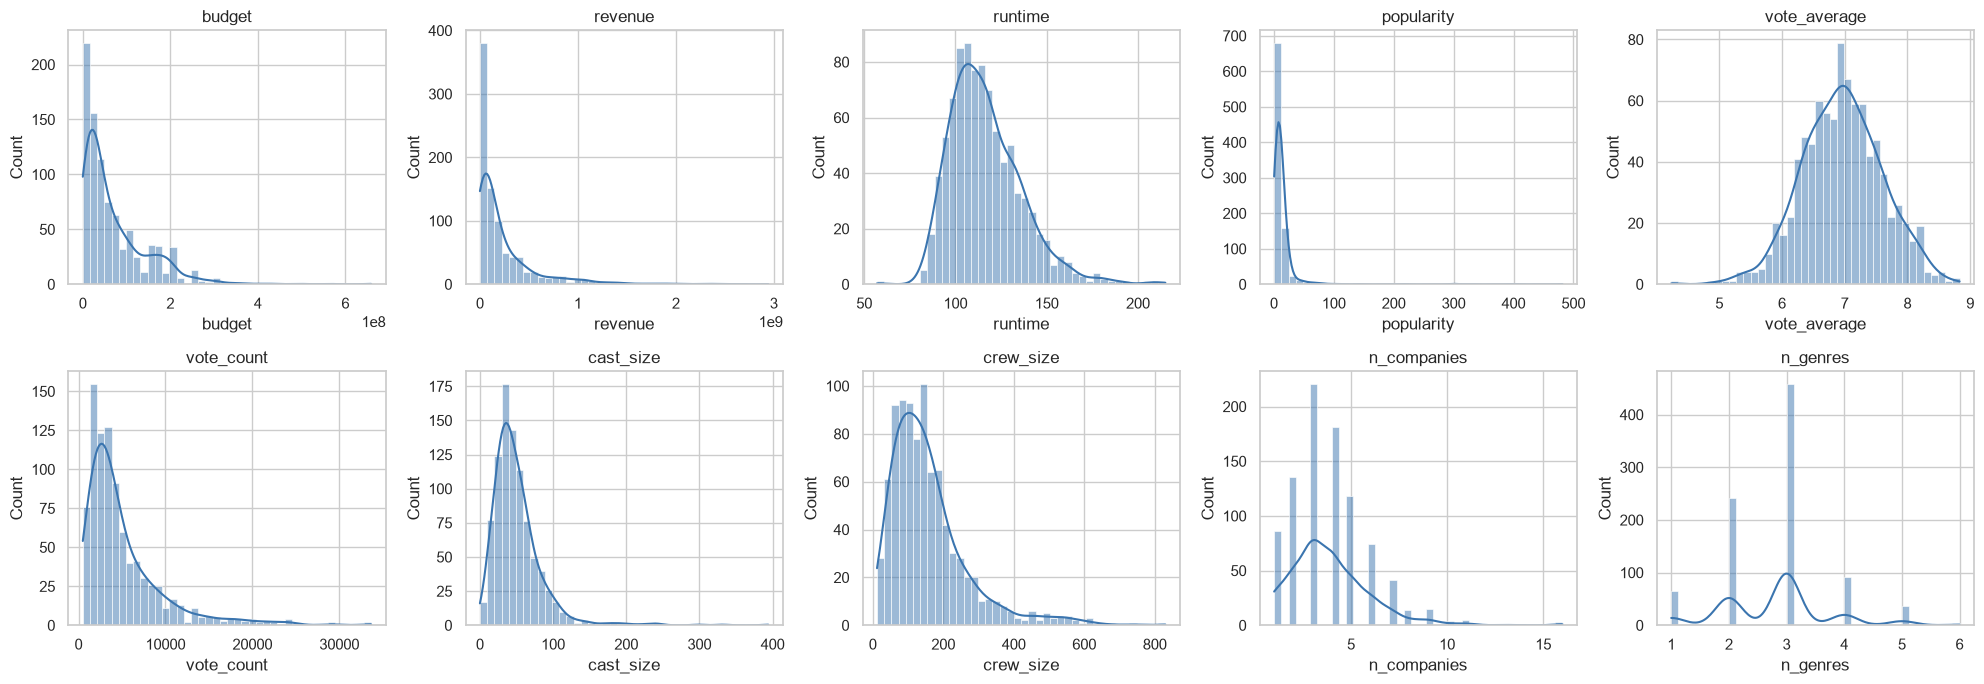

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.ravel(), NUM_EDA):
    sns.histplot(eda[col], bins=40, kde=True, ax=ax, color="#3b75af")
    ax.set_title(col)
save_fig("p2_01_histograms.png")

**What we did:** we drew a histogram (with a smooth density curve) for each of the 10 main numeric columns.

**Why:** the brief asks for histograms, and they show straight away which columns are lopsided.

**What we found:** budget, revenue, popularity, vote count, cast size and crew size are all bunched up on the left with a long tail to the right: most films are modest, and a few are enormous. Runtime and rating look roughly bell-shaped.

### 6.3 Box plots (first look at outliers)

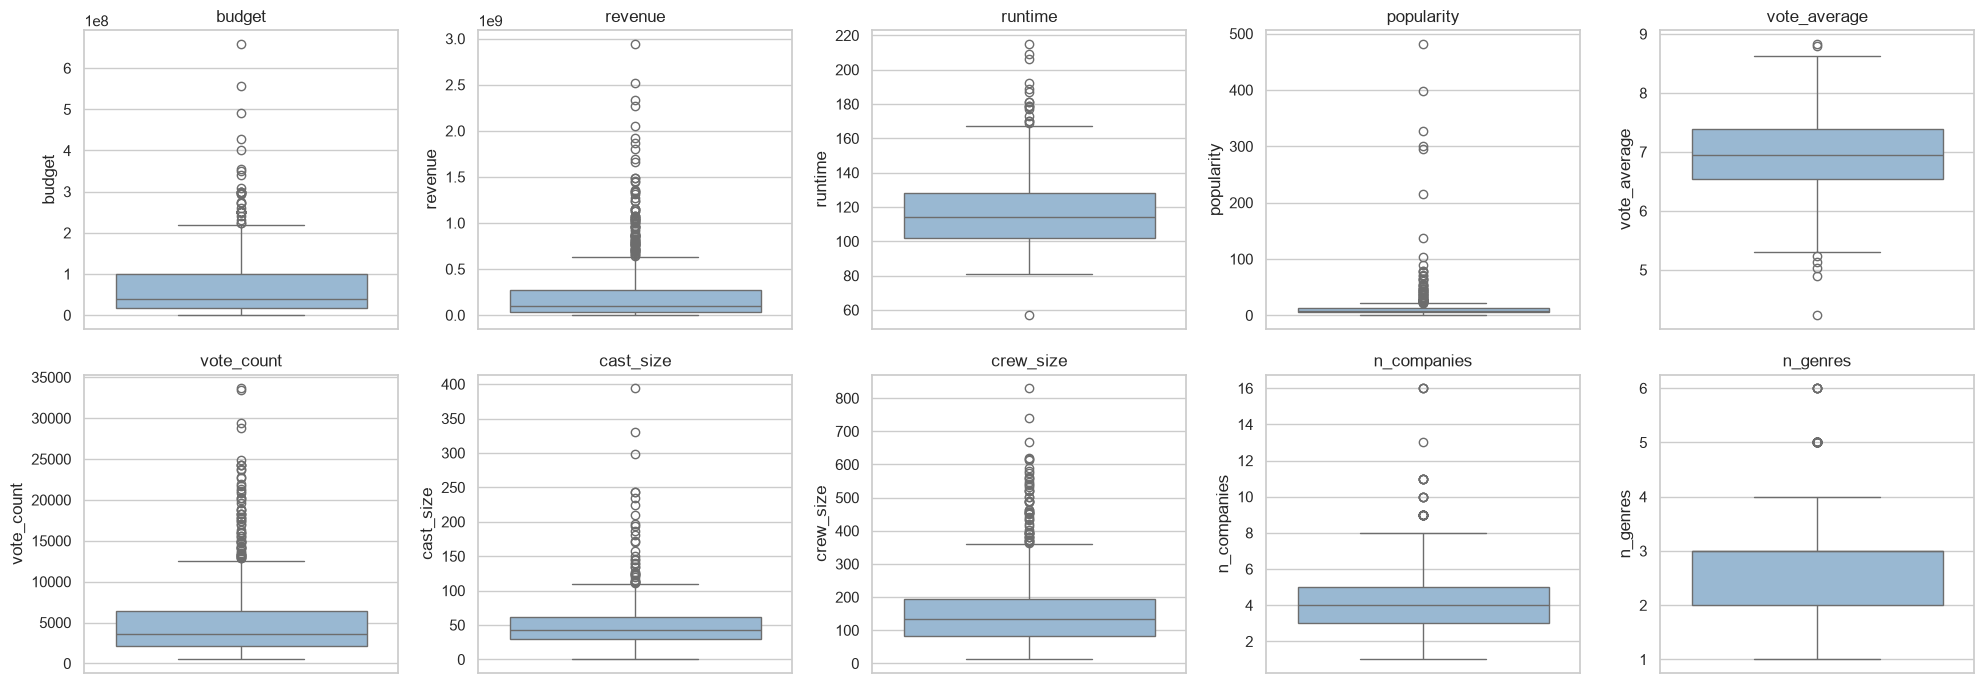

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.ravel(), NUM_EDA):
    sns.boxplot(y=eda[col], ax=ax, color="#8fb9dc")
    ax.set_title(col)
save_fig("p2_02_boxplots.png")

**What we did:** we drew a box plot for each numeric column.

**Why:** box plots mark the points that sit far outside the typical range, so this is a first look at the outliers we study in Section 8.

**What we found:** revenue, budget, popularity and vote count have lots of points above the top whisker. These are big franchise films, not mistakes, so we look at them properly before deciding what to do.

### 6.4 Scatter plots: relationships with revenue

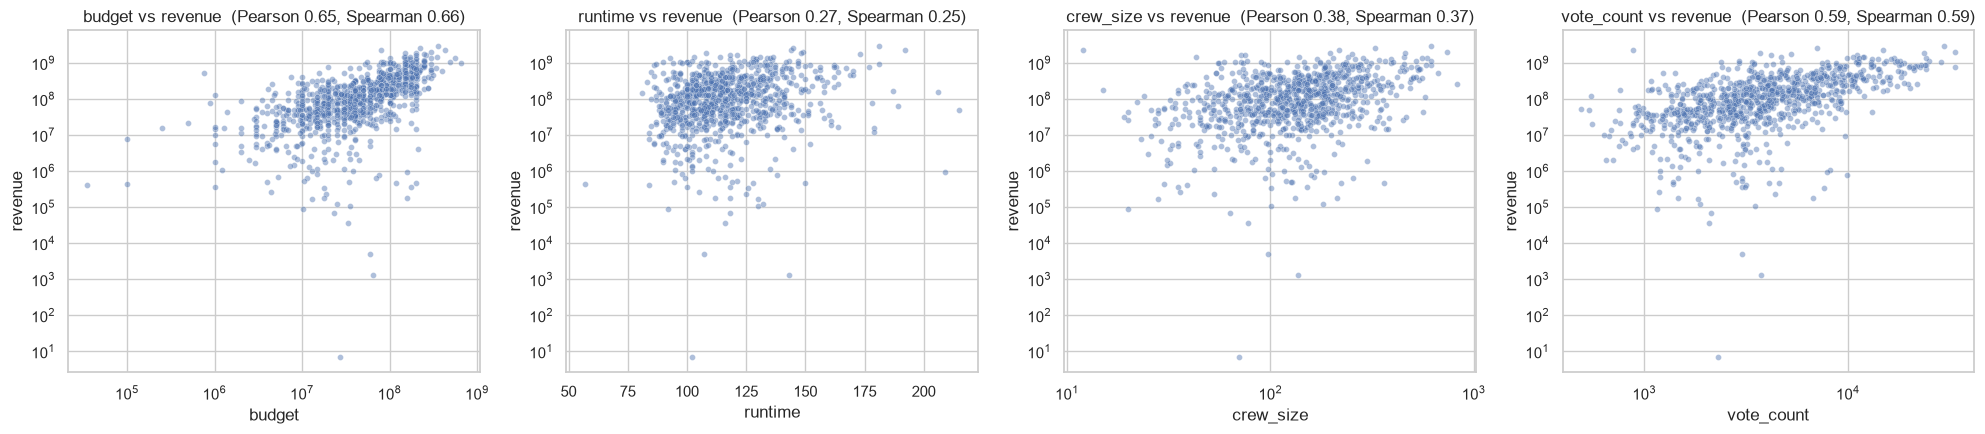

,pair,pearson,spearman
0,budget vs revenue,0.645,0.659
1,runtime vs revenue,0.270,0.247
2,crew_size vs revenue,0.381,0.369
3,vote_count vs revenue,0.590,0.593


In [6]:
pairs = [("budget", "revenue"), ("runtime", "revenue"), ("crew_size", "revenue"), ("vote_count", "revenue")]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
rows = []
for ax, (x, y) in zip(axes, pairs):
    sns.scatterplot(data=eda, x=x, y=y, alpha=0.45, s=18, ax=ax)
    if x in ("budget", "crew_size", "vote_count"):
        ax.set_xscale("log")
    ax.set_yscale("log")
    pr = eda[[x, y]].corr().iloc[0, 1]
    sr = eda[[x, y]].corr(method="spearman").iloc[0, 1]
    ax.set_title(f"{x} vs {y}  (Pearson {pr:.2f}, Spearman {sr:.2f})")
    rows.append({"pair": f"{x} vs {y}", "pearson": round(pr, 3), "spearman": round(sr, 3)})
save_fig("p2_03_scatter.png")
scat = pd.DataFrame(rows); display(scat)
R.update(r_budget=scat.loc[0, "pearson"], s_budget=scat.loc[0, "spearman"], r_runtime=scat.loc[1, "pearson"],
         s_crew=scat.loc[2, "spearman"], s_votes=scat.loc[3, "spearman"])

**What we did:** we plotted revenue against budget, runtime, crew size and vote count (on log scales) and calculated two kinds of correlation for each pair: Pearson (linear) and Spearman (rank-based, less affected by extreme values).

**Why:** this shows which columns move together with revenue, and how strongly.

**What we found:** budget has the strongest link with revenue (Pearson 0.65, Spearman 0.66). On the log scale it looks close to a straight line, which is a good reason to log-transform both. Runtime barely matters (0.27). Crew size has a moderate link (0.37), because bigger productions hire bigger crews. Vote count is also strongly linked (0.59), but votes pile up *after* release, so we come back to that in 9.3.

### 6.5 Bar charts: revenue across movie groups

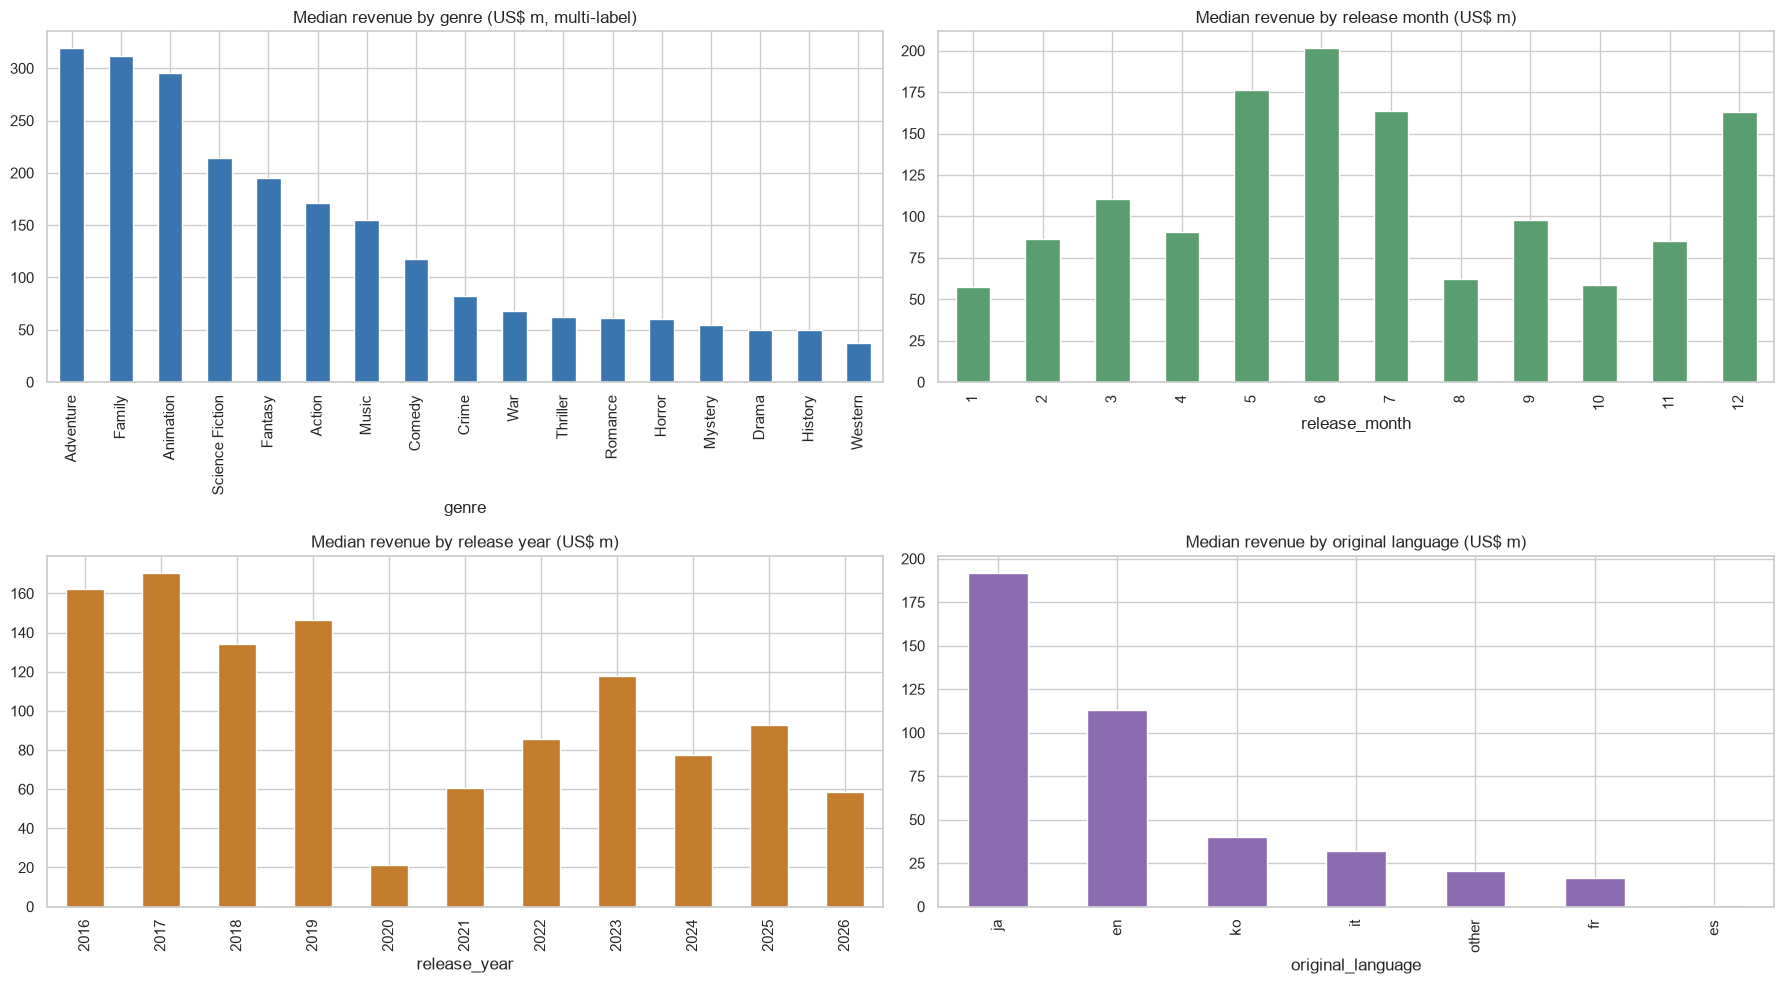

,n,median,mean
genre,,,
Adventure,256,319.3,463.0
Family,109,312.0,448.0
Animation,96,295.3,448.5
Science Fiction,188,213.9,367.5
Fantasy,144,195.3,343.3
Action,312,171.6,327.2
Music,21,154.6,267.1
Comedy,249,118.1,241.2
Crime,126,82.1,145.8


release_year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
n,99.0,94.0,86.0,85.0,64.0,77.0,72.0,83.0,84.0,84.0,71.0
median,162.4,170.7,134.3,146.7,21.4,60.7,85.7,117.6,77.4,92.7,58.5


In [7]:
g = eda.assign(genre=eda["genres"].str.split("|")).explode("genre")
by_genre = g.groupby("genre")["revenue"].agg(n="count", median="median", mean="mean").sort_values("median", ascending=False)
by_month = eda.groupby("release_month")["revenue"].median()
by_year = eda.groupby("release_year")["revenue"].agg(n="count", median="median")
lang = eda["original_language"].where(eda["original_language"].isin(eda["original_language"].value_counts().index[:6]), "other")
by_lang = eda.groupby(lang)["revenue"].agg(n="count", median="median").sort_values("median", ascending=False)

fig, axes = plt.subplots(2, 2, figsize=(18, 10))
(by_genre["median"]/1e6).plot.bar(ax=axes[0, 0], color="#3b75af"); axes[0, 0].set_title("Median revenue by genre (US$ m, multi-label)")
(by_month/1e6).plot.bar(ax=axes[0, 1], color="#5a9e6f"); axes[0, 1].set_title("Median revenue by release month (US$ m)")
(by_year["median"]/1e6).plot.bar(ax=axes[1, 0], color="#c27c2c"); axes[1, 0].set_title("Median revenue by release year (US$ m)")
(by_lang["median"]/1e6).plot.bar(ax=axes[1, 1], color="#8c6bb1"); axes[1, 1].set_title("Median revenue by original language (US$ m)")
save_fig("p2_04_bar_charts.png")
display((by_genre.assign(median=lambda d: d["median"]/1e6, mean=lambda d: d["mean"]/1e6)).round(1))
display((by_year.assign(median=lambda d: d["median"]/1e6)).round(1).T)
R.update(top_genre=by_genre.index[0], top_genre_med=by_genre["median"].iloc[0]/1e6,
         low_genre=by_genre.index[-1], low_genre_med=by_genre["median"].iloc[-1]/1e6,
         top_month=int(by_month.idxmax()), top_month_med=by_month.max()/1e6,
         low_month=int(by_month.idxmin()), low_month_med=by_month.min()/1e6,
         n_2026=int(by_year.loc[2026, "n"]), med_2026=by_year.loc[2026, "median"]/1e6,
         n_2020=int(by_year.loc[2020, "n"]), med_2020=by_year.loc[2020, "median"]/1e6,
         en_share=(eda["original_language"] == "en").mean()*100)

**What we did:** we compared the median revenue across genres, release months, release years and original languages. Each film is counted once for every genre it has.

**Why:** the brief asks for bar charts across groups. We use the median because one blockbuster would distort an average.

**What we found:**
- **Genre:** Adventure films earn the most ($319.3 million median) and Western films the least ($37.3 million).
- **Month:** June releases do best ($201.6 million) and January worst ($57.3 million), which matches the summer blockbuster season.
- **Year:** 2020 stands out as a terrible year, with only 64 films with known revenue and a median of $21.4 million, because cinemas were closed. 2026 isn't over yet (71 films, median $58.5 million).
- **Language:** 93.4% of the films are in English, so the other language groups are small and their bars are less reliable.

### 6.6 Correlation heatmap

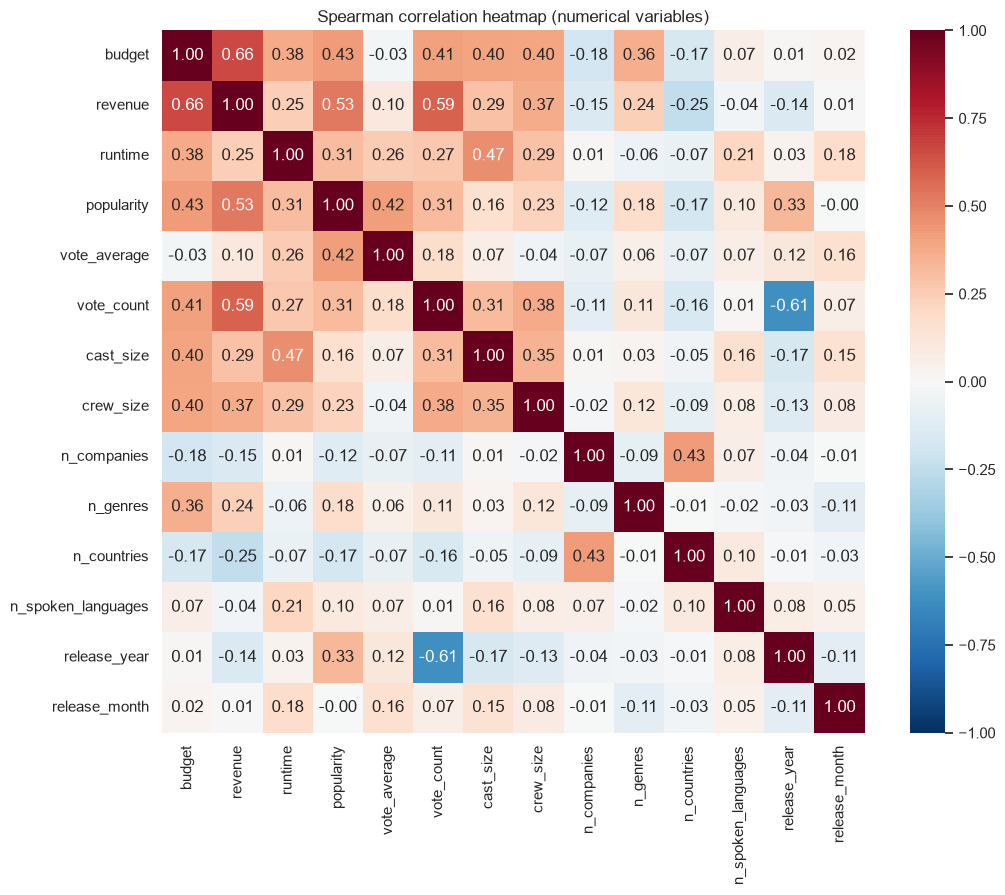

,spearman_with_revenue
budget,0.659
vote_count,0.593
popularity,0.530
crew_size,0.369
cast_size,0.293
n_countries,-0.250
runtime,0.247
n_genres,0.241
n_companies,-0.150
release_year,-0.143


In [8]:
corr_cols = NUM_EDA + ["n_countries", "n_spoken_languages", "release_year", "release_month"]
corr = eda[corr_cols].corr(method="spearman")
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True)
plt.title("Spearman correlation heatmap (numerical variables)")
save_fig("p2_05_correlation_heatmap.png")
tgt = corr["revenue"].drop("revenue").sort_values(key=abs, ascending=False)
display(tgt.round(3).to_frame("spearman_with_revenue"))
R.update(corr_top1=tgt.index[0], corr_top1_v=tgt.iloc[0], corr_top2=tgt.index[1], corr_top2_v=tgt.iloc[1],
         corr_top3=tgt.index[2], corr_top3_v=tgt.iloc[2],
         corr_bud_votes=corr.loc["budget", "vote_count"], corr_year=corr.loc["release_year", "revenue"])

**What we did:** we made a heatmap of Spearman correlations between 14 numeric columns and listed how strongly each one relates to revenue.

**Why:** this shows which columns go with revenue and which inputs overlap with each other.

**What we found:** the strongest links with revenue are budget (0.66), vote_count (0.59) and popularity (0.53). The last two only exist after release, which is a warning sign we deal with in 9.3. Release year has a small negative link (-0.14): newer films have simply had less time to earn.

## 7. Skewness Analysis and Treatment
### 7.1 Skewness of every numerical feature

In [9]:
SKEW_COLS = [c for c in corr_cols if c not in ("release_month",)]
sk = eda[SKEW_COLS].skew().sort_values(ascending=False).to_frame("skewness")
sk["direction"] = np.where(sk["skewness"] > 0, "positive (right)", "negative (left)")
sk["level"] = pd.cut(sk["skewness"].abs(), [-1, 0.5, 1, np.inf], labels=["≈ symmetric", "moderate", "high"])
display(sk.round(3))
R.update(n_high_skew=int((sk["level"] == "high").sum()), n_neg_skew=int((sk["skewness"] < 0).sum()),
         skew_rev=sk.loc["revenue", "skewness"], skew_pop=sk.loc["popularity", "skewness"],
         skew_budget=sk.loc["budget", "skewness"], skew_va=sk.loc["vote_average", "skewness"],
         neg_skew_list=", ".join(sk.index[sk["skewness"] < 0]))

,skewness,direction,level
popularity,10.769,positive (right),high
cast_size,3.372,positive (right),high
revenue,3.115,positive (right),high
n_countries,2.647,positive (right),high
vote_count,2.389,positive (right),high
budget,2.131,positive (right),high
n_spoken_languages,2.079,positive (right),high
crew_size,1.893,positive (right),high
n_companies,1.416,positive (right),high
runtime,1.054,positive (right),high


**What we did:** we calculated the skewness of every numeric column, noted whether it leans right (positive) or left (negative), and labelled it as roughly symmetric (under 0.5), moderate (0.5–1) or high (above 1).

**Why:** heavily skewed columns cause problems for linear models and let a few extreme films dominate the errors.

**What we found:** 10 columns are highly skewed, and all of them lean right: popularity (10.77), revenue (3.11) and budget (2.13) are the worst. Only vote_average leans left, and only slightly (-0.08), so it doesn't need fixing.

### 7.2 Transformations: log1p vs Yeo-Johnson

In [10]:
TRANSFORM_COLS = sk.index[(sk["level"] == "high") & (eda[sk.index].min() >= 0)].tolist()
rows = []
for c in TRANSFORM_COLS:
    x = eda[c].astype(float)
    yj = PowerTransformer(method="yeo-johnson").fit_transform(x.to_frame()).ravel()
    rows.append({"feature": c, "before": x.skew(), "log1p": np.log1p(x).skew(), "yeo_johnson": pd.Series(yj).skew()})
skew_cmp = pd.DataFrame(rows).set_index("feature")
skew_cmp["best"] = skew_cmp[["log1p", "yeo_johnson"]].abs().idxmin(axis=1)
skew_cmp["improved"] = skew_cmp[["log1p", "yeo_johnson"]].abs().min(axis=1) < skew_cmp["before"].abs()
display(skew_cmp.round(3))
print("Not transformed (skew already acceptable or has a natural bound):",
      [c for c in SKEW_COLS if c not in TRANSFORM_COLS])
R.update(transform_cols=", ".join(TRANSFORM_COLS), n_transform=len(TRANSFORM_COLS),
         rev_log_skew=skew_cmp.loc["revenue", "log1p"], rev_yj_skew=skew_cmp.loc["revenue", "yeo_johnson"],
         bud_log_skew=skew_cmp.loc["budget", "log1p"] if "budget" in skew_cmp.index else float("nan"),
         n_improved=int(skew_cmp["improved"].sum()))

,before,log1p,yeo_johnson,best,improved
feature,,,,,
popularity,10.769,1.639,-0.119,yeo_johnson,True
cast_size,3.372,-0.372,0.037,yeo_johnson,True
revenue,3.115,-1.798,-0.008,yeo_johnson,True
n_countries,2.647,1.361,0.572,yeo_johnson,True
vote_count,2.389,0.191,0.008,yeo_johnson,True
budget,2.131,-0.829,-0.032,yeo_johnson,True
n_spoken_languages,2.079,1.162,-0.063,yeo_johnson,True
crew_size,1.893,-0.188,0.000,yeo_johnson,True
n_companies,1.416,-0.103,-0.000,yeo_johnson,True


Not transformed (skew already acceptable or has a natural bound): ['vote_average', 'n_genres', 'release_year']


**What we did:** for each highly skewed, non-negative column, we compared the skewness before any change, after `log1p` (log of 1 + x), and after Yeo-Johnson (a transform that picks the best power automatically).

**Why:** the brief says not to transform everything blindly, so we only touch the highly skewed columns and compare two options.

**What we found:** both transforms reduced the skew for all 10 columns. For revenue, `log1p` actually overshoots (from 3.11 to -1.80, because a handful of films report tiny revenues), while Yeo-Johnson gets almost perfectly symmetric (-0.01). We still use `log1p` for revenue, because it's easy to undo (`expm1` turns predictions back into dollars) and its errors read like percentages. **What we use in the model:** `log1p` on budget, cast size, crew size and company count. Popularity and vote count are dropped (see 9.3).

### 7.3 Distributions before and after transformation

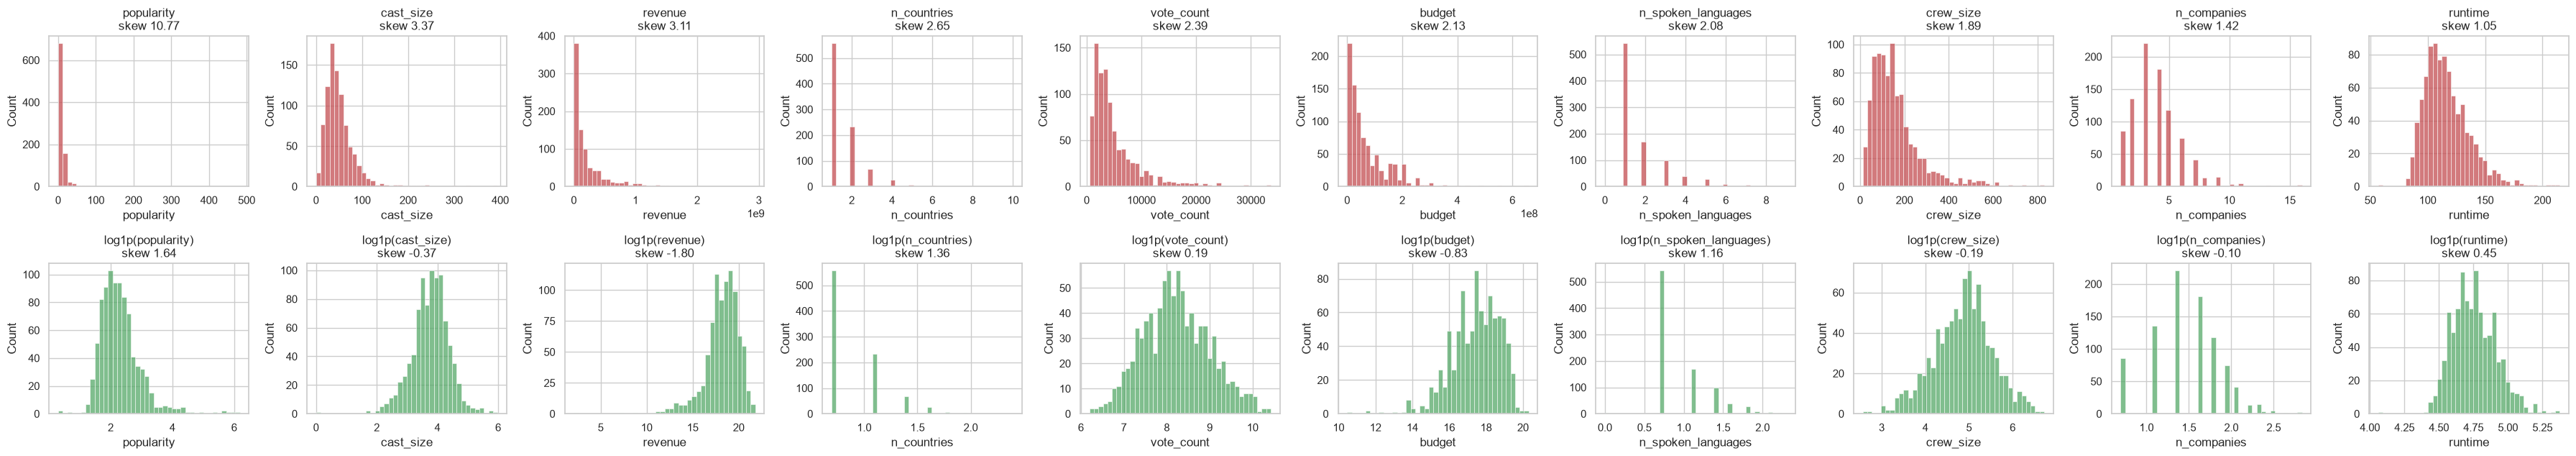

In [11]:
fig, axes = plt.subplots(2, len(TRANSFORM_COLS), figsize=(3.6*len(TRANSFORM_COLS), 6.5))
for i, c in enumerate(TRANSFORM_COLS):
    sns.histplot(eda[c], bins=40, ax=axes[0, i], color="#c44e52"); axes[0, i].set_title(f"{c}\nskew {eda[c].skew():.2f}")
    sns.histplot(np.log1p(eda[c]), bins=40, ax=axes[1, i], color="#55a868"); axes[1, i].set_title(f"log1p({c})\nskew {np.log1p(eda[c]).skew():.2f}")
save_fig("p2_06_skew_before_after.png")

**What we did:** we plotted each column before (top row) and after `log1p` (bottom row), with the skewness in each title.

**Why:** the brief asks for before-and-after distributions, not just numbers.

**What we found:** after the log transform, budget, vote count and crew size look much more like a bell curve. Log-revenue has a short tail on the left made of the few films with tiny reported revenue (see 8.2), which explains its negative skew.

## 8. Outlier Detection Using the IQR Method
### 8.1 Q1, Q3, IQR, fences and outlier counts

In [12]:
IQR_COLS = ["budget", "revenue", "runtime", "cast_size", "crew_size", "n_companies", "n_countries", "n_spoken_languages", "popularity", "vote_count"]
def iqr_table(df, cols):
    out = []
    for c in cols:
        q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
        lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
        out.append({"feature": c, "Q1": q1, "Q3": q3, "IQR": iqr, "lower_fence": lo, "upper_fence": hi,
                    "n_low": int((df[c] < lo).sum()), "n_high": int((df[c] > hi).sum())})
    t = pd.DataFrame(out).set_index("feature"); t["n_outliers"] = t["n_low"] + t["n_high"]
    t["pct"] = 100 * t["n_outliers"] / len(df)
    return t
iqr_raw = iqr_table(eda, IQR_COLS)
display(iqr_raw.round(1))
R.update(out_rev=int(iqr_raw.loc["revenue", "n_outliers"]), out_bud=int(iqr_raw.loc["budget", "n_outliers"]),
         out_run=int(iqr_raw.loc["runtime", "n_outliers"]), out_pop=int(iqr_raw.loc["popularity", "n_outliers"]),
         out_crew=int(iqr_raw.loc["crew_size", "n_outliers"]), out_cast=int(iqr_raw.loc["cast_size", "n_outliers"]),
         rev_upper=iqr_raw.loc["revenue", "upper_fence"]/1e6, bud_upper=iqr_raw.loc["budget", "upper_fence"]/1e6,
         out_total_raw=int(iqr_raw["n_outliers"].sum()))

,Q1,Q3,IQR,lower_fence,upper_fence,n_low,n_high,n_outliers,pct
feature,,,,,,,,,
budget,17000000.0,100000000.0,83000000.0,-107500000.0,224500000.0,0,36,36,4.0
revenue,34276544.5,274975401.5,240698857.0,-326771741.0,636023687.0,0,85,85,9.5
runtime,102.0,128.0,26.0,63.0,167.0,1,16,17,1.9
cast_size,30.0,62.0,32.0,-18.0,110.0,0,35,35,3.9
crew_size,82.5,195.0,112.5,-86.2,363.8,0,51,51,5.7
n_companies,3.0,5.0,2.0,0.0,8.0,0,28,28,3.1
n_countries,1.0,2.0,1.0,-0.5,3.5,0,39,39,4.3
n_spoken_languages,1.0,2.0,1.0,-0.5,3.5,0,84,84,9.3
popularity,5.4,12.3,6.8,-4.8,22.5,0,67,67,7.5


**What we did:** for 10 numeric columns we worked out Q1 and Q3 (the 25th and 75th percentiles), the IQR (Q3 − Q1), and the fences at Q1 − 1.5×IQR and Q3 + 1.5×IQR. Then we counted the values outside the fences.

**Why:** this is the IQR outlier method the brief asks for. It's based on quartiles, so the extreme values can't distort it.

**What we found:** revenue has 85 outliers (anything above $636.0 million), budget 36 (above $224.5 million), popularity 67, crew size 51, cast size 35 and runtime 17. Almost all of them are on the high side, which is what you'd expect from right-skewed data.

### 8.2 Investigating the outliers before acting

In [13]:
hi_rev = eda.loc[eda["revenue"] > iqr_raw.loc["revenue", "upper_fence"], ["title", "release_year", "budget", "revenue", "primary_genre", "in_collection"]]
print(f"Revenue outliers above the upper fence: {len(hi_rev)}  |  share that belong to a franchise collection: {hi_rev['in_collection'].mean():.0%}")
display(hi_rev.sort_values("revenue", ascending=False).head(10).assign(budget=lambda d: d["budget"]/1e6, revenue=lambda d: d["revenue"]/1e6).round(1))
long = eda.loc[eda["runtime"] > iqr_raw.loc["runtime", "upper_fence"], ["title", "runtime"]].sort_values("runtime", ascending=False)
display(long.head(5))
low_rev = eda.loc[eda["revenue"] < 1e6, ["title", "release_year", "budget", "revenue", "original_language"]].sort_values("revenue")
print(f"Films with revenue below US$1m: {len(low_rev)} | revenue lower fence = {iqr_raw.loc['revenue', 'lower_fence']/1e6:.1f} m, so IQR flags {int(iqr_raw.loc['revenue', 'n_low'])} of them")
display(low_rev.head(8))
R.update(n_low_rev=len(low_rev), min_rev=eda["revenue"].min(), min_rev_title=low_rev.iloc[0]["title"],
         hi_rev_coll=hi_rev["in_collection"].mean()*100, top_rev_title=hi_rev.sort_values("revenue").iloc[-1]["title"],
         longest_title=long.iloc[0]["title"], longest_rt=int(long.iloc[0]["runtime"]))

Revenue outliers above the upper fence: 85  |  share that belong to a franchise collection: 88%


,title,release_year,budget,revenue,primary_genre,in_collection
279,Avengers: Endgame,2019,356.0,2942.7,Adventure,True
829,Spider-Man: Brand New Day,2026,225.0,2523.1,Science Fiction,True
505,Avatar: The Way of Water,2022,428.5,2334.5,Action,True
826,Ne Zha 2,2025,80.0,2270.7,Animation,True
193,Avengers: Infinity War,2018,300.0,2052.4,Adventure,True
428,Spider-Man: No Way Home,2021,200.0,1921.4,Action,True
756,Zootopia 2,2025,150.0,1868.2,Adventure,True
831,The Odyssey,2026,250.0,1804.6,Adventure,False
662,Inside Out 2,2024,200.0,1698.9,Action,True
290,The Lion King,2019,260.0,1662.0,Adventure,True


,title,runtime
710,The Brutalist,215.0
305,The Irishman,209.0
594,Killers of the Flower Moon,206.0
505,Avatar: The Way of Water,192.0
537,Babylon,189.0


Films with revenue below US$1m: 29 | revenue lower fence = -326.8 m, so IQR flags 0 of them


,title,release_year,budget,revenue,original_language
846,Swapped,2026,2.684088e+07,7.0,en
605,Society of the Snow,2023,6.550000e+07,1281.0,es
692,Damsel,2024,6.000000e+07,5000.0,en
708,The Idea of You,2024,3.333664e+07,36178.0,en
403,The Midnight Sky,2020,2.331734e+07,70018.0,en
737,Don't Move,2024,1.030557e+07,88489.0,en
391,The Trial of the Chicago 7,2020,3.500000e+07,107423.0,en
409,Mank,2020,2.500000e+07,122252.0,en


**What we did:** we listed the biggest revenue outliers and checked how many are franchise films. We also looked at the longest films and at the films reporting under $1 million.

**Why:** extreme values can be perfectly real. We wanted to understand them before deciding what to do.

**What we found:** the top outlier is *Avengers: Endgame*, and 88% of the revenue outliers belong to a franchise. These are real blockbusters, so **we keep them**: removing them would teach the model that blockbusters don't exist. The longest film, *The Brutalist* (215 minutes), is real too. We also found 29 films reporting under $1 million (the lowest is *Swapped* at $7). Many of these are streaming releases with placeholder numbers, and the IQR method can't catch them because its lower fence is below zero. We keep them too, since there's no clear rule for removing them, and list them as a limitation.

### 8.3 Outlier treatment and box plots before/after

,raw,after_log1p,after_log1p_and_capping
feature,,,
budget,36,14,0
runtime,17,17,0
cast_size,35,28,0
crew_size,51,9,0
n_companies,28,95,0


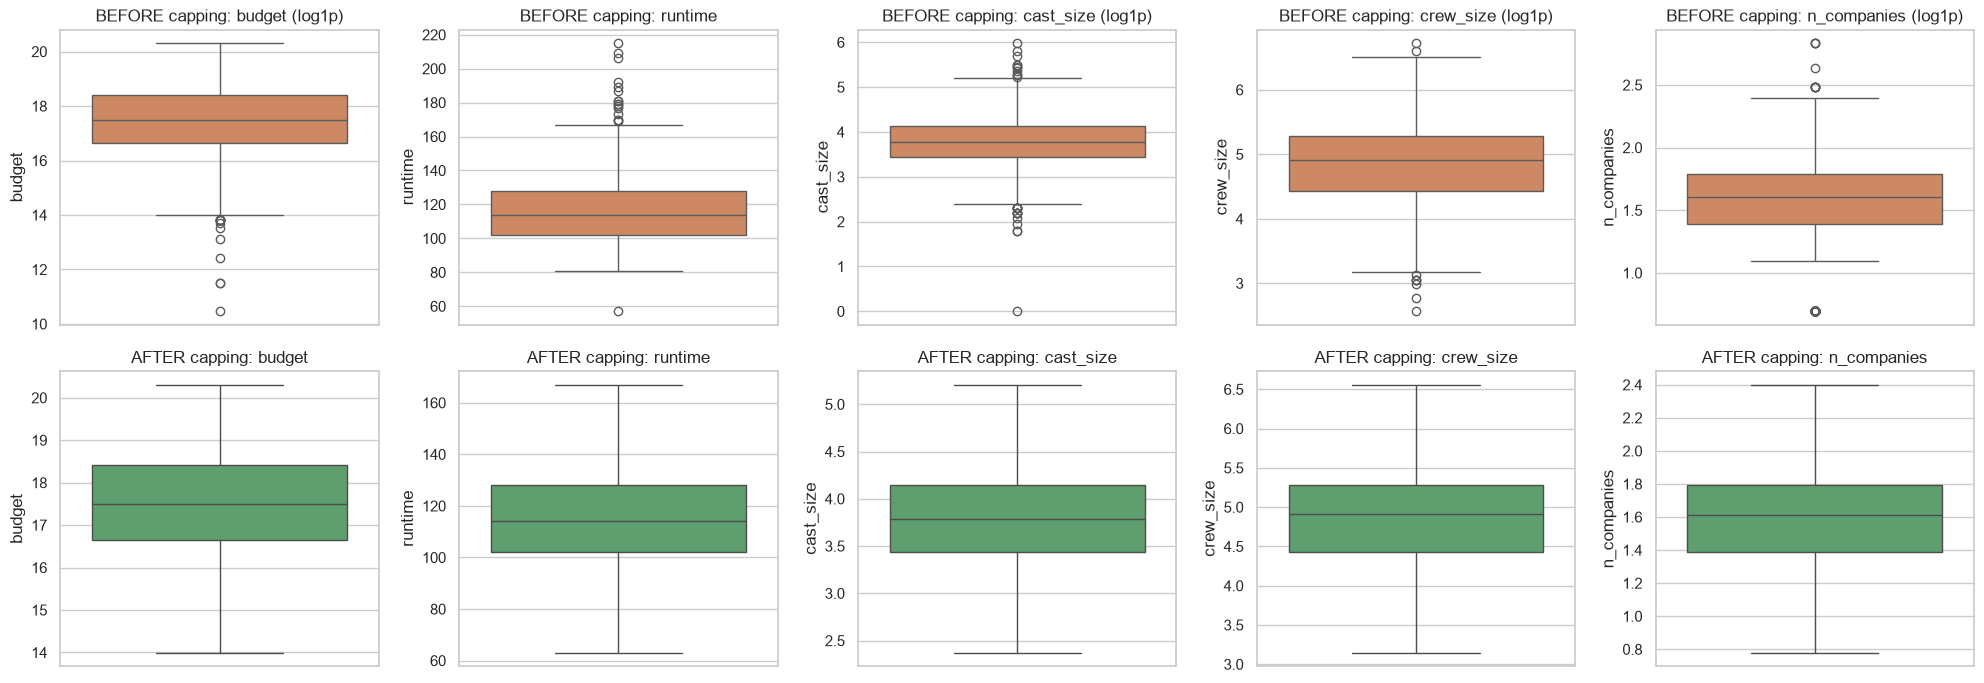

In [14]:
class IQRCapper(BaseEstimator, TransformerMixin):
    """Caps each column at the IQR fences learned on the data it is fitted on (the training set)."""
    def __init__(self, k=1.5):
        self.k = k
    def fit(self, X, y=None):
        if hasattr(X, "columns"):
            self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        X = np.asarray(X, dtype=float)
        self.n_features_in_ = X.shape[1]
        q1, q3 = np.nanpercentile(X, 25, axis=0), np.nanpercentile(X, 75, axis=0)
        self.lo_, self.hi_ = q1 - self.k*(q3 - q1), q3 + self.k*(q3 - q1)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)
    def get_feature_names_out(self, input_features=None):
        return _check_feature_names_in(self, input_features)

LOG_FEATS = ["budget", "cast_size", "crew_size", "n_companies"]
demo = eda[["budget", "runtime", "cast_size", "crew_size", "n_companies"]].copy()
demo_log = demo.copy(); demo_log[LOG_FEATS] = np.log1p(demo_log[LOG_FEATS])
demo_cap = pd.DataFrame(IQRCapper().fit_transform(demo_log), columns=demo.columns)
cmp_out = pd.DataFrame({"raw": iqr_table(demo, demo.columns)["n_outliers"],
                        "after_log1p": iqr_table(demo_log, demo.columns)["n_outliers"],
                        "after_log1p_and_capping": iqr_table(demo_cap, demo.columns)["n_outliers"]})
display(cmp_out)
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for i, c in enumerate(demo.columns):
    sns.boxplot(y=demo_log[c], ax=axes[0, i], color="#dd8452"); axes[0, i].set_title(f"BEFORE capping: {c}" + (" (log1p)" if c in LOG_FEATS else ""))
    sns.boxplot(y=demo_cap[c], ax=axes[1, i], color="#55a868"); axes[1, i].set_title(f"AFTER capping: {c}")
save_fig("p2_07_outliers_before_after.png")
R.update(out_bud_log=int(cmp_out.loc["budget", "after_log1p"]), out_run_raw=int(cmp_out.loc["runtime", "raw"]),
         out_sum_raw=int(cmp_out["raw"].sum()), out_sum_log=int(cmp_out["after_log1p"].sum()),
         out_sum_cap=int(cmp_out["after_log1p_and_capping"].sum()))

**What we did:** we built a small `IQRCapper` tool that learns the fences from the data and pulls any value outside them back to the fence (this is called capping). On the EDA copy we applied it after `log1p` to budget, cast size, crew size and company count, and directly to runtime.

**Why:** capping keeps every film but stops one extreme value from pulling a linear model too far. In the real model pipeline the fences are learned from the **training movies only**, and revenue itself is never capped.

**What we found:** across these five columns, outliers drop from 167 (raw) to 163 after the log transform, and to 0 after capping. For budget alone, the log transform cuts outliers from 36 to 14. So many of the "outliers" were really just skew. The after box plots show no points beyond the whiskers, and no films were deleted.

## 9. Feature Engineering and Feature Selection
### 9.1 Derived features

In [15]:
GENRES = sorted(set("|".join(base["genres"].dropna()).split("|")))
SEASON = {12: "holiday", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "summer", 6: "summer",
          7: "summer", 8: "late_summer", 9: "autumn", 10: "autumn", 11: "holiday"}

def engineer(df):
    out = pd.DataFrame(index=df.index)
    out["budget"] = df["budget"]
    out["budget_missing"] = df["budget"].isna().astype(int)
    out["runtime"] = df["runtime"].astype(float)
    for c in ["n_genres", "n_companies", "n_countries", "n_spoken_languages", "cast_size", "crew_size", "release_year"]:
        out[c] = df[c].astype(float)
    out["release_month"] = df["release_month"]
    out["release_dow"] = df["release_dow"]
    out["is_weekend_release"] = df["release_dow"].isin([4, 5, 6]).astype(int)   # Fri/Sat/Sun (0 = Monday)
    for c in ["has_homepage", "has_tagline", "in_collection"]:
        out[c] = df[c].astype(int)
    out["is_english"] = (df["original_language"] == "en").astype(int)
    out["us_production"] = df["production_countries"].fillna("").str.contains("United States of America").astype(int)
    for gname in GENRES:
        out["genre_" + gname.lower().replace(" ", "_")] = df["genres"].fillna("").str.split("|").apply(lambda L: int(gname in L))
    out["season"] = df["release_month"].map(SEASON)
    out["original_language"] = df["original_language"]
    out["primary_country"] = df["primary_country"]
    out["primary_company"] = df["primary_company"]
    out["director"] = df["director"]
    return out

X_all = engineer(base)
y_all = np.log1p(base["revenue"])               # model log-revenue; dollars are recovered with expm1
GENRE_COLS = [c for c in X_all if c.startswith("genre_")]
dict_rows = [(c, str(X_all[c].dtype), "multi-hot from genres" if c.startswith("genre_") else "") for c in X_all.columns]
print("Engineered feature matrix:", X_all.shape, "| genre dummies:", len(GENRE_COLS))
display(X_all.head(3))
R.update(n_eng_cols=X_all.shape[1], n_genre_cols=len(GENRE_COLS))

Engineered feature matrix: (899, 40) | genre dummies: 17


,budget,budget_missing,runtime,n_genres,n_companies,n_countries,n_spoken_languages,cast_size,crew_size,release_year,release_month,release_dow,is_weekend_release,has_homepage,has_tagline,in_collection,is_english,us_production,genre_action,genre_adventure,genre_animation,genre_comedy,genre_crime,genre_drama,genre_family,genre_fantasy,genre_history,genre_horror,genre_music,genre_mystery,genre_romance,genre_science_fiction,genre_thriller,genre_war,genre_western,season,original_language,primary_country,primary_company,director
0,58000000.0,0,108.0,3.0,4.0,1.0,1.0,52.0,489.0,2016.0,2,1,0,1,1,1,1,1,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,winter,en,United States of America,20th Century Fox,Tim Miller
1,250000000.0,0,147.0,3.0,1.0,1.0,4.0,104.0,296.0,2016.0,4,2,0,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,spring,en,United States of America,Marvel Studios,Joe Russo
2,180000000.0,0,115.0,3.0,1.0,1.0,1.0,44.0,253.0,2016.0,10,1,0,1,1,1,1,1,1,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,autumn,en,United States of America,Marvel Studios,Scott Derrickson


**What we did:** we wrote an `engineer()` function that builds our model inputs:
- **from the release date:** year, month, weekday, "released on a weekend", and season;
- **from the nested lists:** 17 yes/no genre columns (a film can have several), "US production", and the number of genres, companies, countries, languages, cast and crew;
- **yes/no flags:** has a homepage, has a tagline, part of a franchise, in English, budget unknown;
- **categories to one-hot encode:** season, language, main country and main company. Director is kept for Section 14.

The target is `log1p(revenue)`.

**Why:** the brief asks for date-based and nested features, several categorical columns, and proper handling of multi-value fields. With yes/no genre columns we keep *every* genre of a film, not just the first. The "budget unknown" flag lets the model learn that those films behave differently.

**What we found:** the feature table has 899 rows and 40 columns. IDs, titles, plot text and the post-release statistics are deliberately left out.

### 9.2 Meaning and type of every model attribute

In [16]:
DATA_DICT = {
 "budget": ("numeric", "Production budget in USD (NaN when TMDB has 0). log1p + IQR capping in the pipeline"),
 "budget_missing": ("Boolean", "1 if the budget was unknown, so the model can learn that missing budgets behave differently"),
 "runtime": ("numeric", "Length in minutes"),
 "n_genres / n_companies / n_countries / n_spoken_languages": ("numeric (count)", "Counts derived from nested API lists"),
 "cast_size / crew_size": ("numeric (count)", "Size of credited cast and crew from the credits endpoint"),
 "release_year / release_month / release_dow": ("date-derived", "Parts of release_date"),
 "is_weekend_release": ("Boolean, date-derived", "Released Friday to Sunday"),
 "season": ("categorical, date-derived", "Release window (summer, holiday, ...), one-hot encoded"),
 "has_homepage / has_tagline / in_collection": ("Boolean", "Marketing signals and franchise membership"),
 "is_english / us_production": ("Boolean", "Derived from original_language / production_countries"),
 "genre_*": ("Boolean (multi-hot)", "One column per genre after splitting the '|' list"),
 "original_language / primary_country / primary_company": ("categorical", "One-hot encoded; rare levels grouped as 'infrequent' (min_frequency, fitted on train)"),
 "director": ("categorical, high cardinality", "Only used by the target-encoding experiment (Advanced Technique #2)"),
 "TARGET: log1p(revenue)": ("numeric", "Box-office revenue (USD), log-transformed for training"),
}
display(pd.DataFrame(DATA_DICT, index=["type", "meaning"]).T)

,type,meaning
budget,numeric,Production budget in USD (NaN when TMDB has 0)...
budget_missing,Boolean,"1 if the budget was unknown, so the model can ..."
runtime,numeric,Length in minutes
n_genres / n_companies / n_countries / n_spoken_languages,numeric (count),Counts derived from nested API lists
cast_size / crew_size,numeric (count),Size of credited cast and crew from the credit...
release_year / release_month / release_dow,date-derived,Parts of release_date
is_weekend_release,"Boolean, date-derived",Released Friday to Sunday
season,"categorical, date-derived","Release window (summer, holiday, ...), one-hot..."
has_homepage / has_tagline / in_collection,Boolean,Marketing signals and franchise membership
is_english / us_production,Boolean,Derived from original_language / production_co...


**What we did:** we wrote down the meaning and type of every input the model uses.

**Why:** the brief asks for every selected attribute to be documented.

**What we found:** we have numeric, date-based, yes/no, multi-hot and categorical inputs, and every one of them is known **before** a film is released. That's the moment we're predicting from: think of a studio estimating box office while the film is still being made.

### 9.3 Target-leakage check

In [17]:
LEAK_COLS = ["popularity", "vote_average", "vote_count"]
leak = base[LEAK_COLS + ["revenue"]].corr(method="spearman")["revenue"].drop("revenue").to_frame("spearman_with_revenue")
display(leak.round(3))
DROP_COLS = ["id", "imdb_id", "title", "original_title", "overview", "tagline", "collection_name", "release_date",
             "status", "adult", "video", "top_cast", "production_companies", "production_countries", "genres", "primary_genre"]
print("Constant columns:", [c for c in ["status", "adult", "video"] if base[c].nunique() == 1])
R.update(leak_votes=leak.loc["vote_count", "spearman_with_revenue"], leak_pop=leak.loc["popularity", "spearman_with_revenue"],
         leak_va=leak.loc["vote_average", "spearman_with_revenue"])

,spearman_with_revenue
popularity,0.539
vote_average,0.101
vote_count,0.601


Constant columns: ['status', 'adult', 'video']


**What we did:** we checked how strongly the after-release statistics (popularity, vote count, rating) are linked to revenue, and listed the columns we leave out.

**Why:** using information that only exists after the outcome would be like reading the answer before the exam. This is called target leakage.

**What we found:** vote count (0.60) and popularity (0.54) are strongly linked to revenue *because* successful films get watched and rated by more people. They're a result of revenue, not a cause, so we **drop them**. Rating (0.10) is only weakly linked, but it's also post-release, so it goes too. `status`, `adult` and `video` have the same value for every film, so they tell the model nothing. IDs, titles, plot text and the raw lists aren't used as numeric features. In 12.6 we measure how much the leaky columns *would* have inflated our scores.

## 10. Train–Test Split (80/20) and Preprocessing
### 10.1 Stratified split

In [18]:
strata = pd.qcut(y_all, q=5, labels=False)          # stratify on revenue quintiles
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.20, random_state=SEED, stratify=strata)
assert len(X_train) + len(X_test) == len(base)          # every film is in exactly one of the two sets
assert set(X_train.index).isdisjoint(X_test.index)
assert not set(base.loc[X_train.index, "id"]) & set(base.loc[X_test.index, "id"])
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Mean log-revenue train {y_train.mean():.3f} vs test {y_test.mean():.3f}")
R.update(n_train=len(X_train), n_test=len(X_test), ytr_mean=y_train.mean(), yte_mean=y_test.mean())

Train: (719, 40) | Test: (180, 40)
Mean log-revenue train 18.191 vs test 18.145


**What we did:** we split the 899 movies 80/20 into 719 for training and 180 for testing, using `random_state = SEED`. The split is stratified by revenue level. We then checked that the sizes add up and that no movie appears in both sets.

**Why:** revenue is very uneven. A purely random split could put most blockbusters on one side by bad luck, while stratifying keeps a similar mix in both. The test set stays untouched until the final evaluation.

**What we found:** the average log-revenue is 18.191 for training and 18.145 for testing, almost the same, so the split is balanced. All the checks passed.

### 10.2 Preprocessing pipeline fitted on the training set only

In [19]:
NUM_LOG   = ["budget", "cast_size", "crew_size", "n_companies"]
NUM_PLAIN = ["runtime", "n_genres", "n_countries", "n_spoken_languages"]
DATE_NUM  = ["release_year", "release_month", "release_dow"]   # date parts: scaled, never capped
BOOL_COLS = ["budget_missing", "is_weekend_release", "has_homepage", "has_tagline", "in_collection", "is_english", "us_production"] + GENRE_COLS
CAT_COLS  = ["season", "original_language", "primary_country", "primary_company"]

def make_preprocessor(cat_cols=CAT_COLS, te_cols=()):
    log_pipe   = Pipeline([("impute", SimpleImputer(strategy="median")), ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                           ("cap", IQRCapper()), ("scale", StandardScaler())])
    plain_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("cap", IQRCapper()), ("scale", StandardScaler())])
    cat_pipe   = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                           ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False))])
    date_pipe  = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    parts = [("log", log_pipe, NUM_LOG), ("num", plain_pipe, NUM_PLAIN), ("date", date_pipe, DATE_NUM),
             ("bool", "passthrough", BOOL_COLS), ("cat", cat_pipe, list(cat_cols))]
    if te_cols:
        parts.append(("te", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="unknown")),
                                      ("te", TargetEncoder(target_type="continuous", cv=5, random_state=SEED))]), list(te_cols)))
    return ColumnTransformer(parts, verbose_feature_names_out=False)

prep = make_preprocessor()
Xtr = pd.DataFrame(prep.fit_transform(X_train), columns=prep.get_feature_names_out(), index=X_train.index)   # fit on TRAIN only
Xte = pd.DataFrame(prep.transform(X_test), columns=prep.get_feature_names_out(), index=X_test.index)          # transform only
assert not Xtr.isna().any().any() and not Xte.isna().any().any()
assert not any(c in Xtr.columns for c in LEAK_COLS + ["revenue"])
print("Preprocessed train:", Xtr.shape, "| test:", Xte.shape)
print("One-hot columns:", [c for c in Xtr.columns if any(c.startswith(p + "_") for p in CAT_COLS)])
pd.concat([Xtr, y_train.rename("log_revenue")], axis=1).to_csv(os.path.join(DATA_DIR, "tmdb_movies_preprocessed_train.csv"), index_label="row")
pd.concat([Xte, y_test.rename("log_revenue")], axis=1).to_csv(os.path.join(DATA_DIR, "tmdb_movies_preprocessed_test.csv"), index_label="row")
R.update(n_prep_cols=Xtr.shape[1], n_ohe=int(sum(any(c.startswith(p + "_") for p in CAT_COLS) for c in Xtr.columns)),
         budget_median_train=float(prep.named_transformers_["log"].named_steps["impute"].statistics_[0])/1e6)

Preprocessed train: (719, 65) | test: (180, 65)
One-hot columns: ['season_autumn', 'season_holiday', 'season_late_summer', 'season_spring', 'season_summer', 'season_winter', 'original_language_en', 'original_language_fr', 'original_language_infrequent_sklearn', 'primary_country_Australia', 'primary_country_Canada', 'primary_country_China', 'primary_country_France', 'primary_country_Japan', 'primary_country_United Kingdom', 'primary_country_United States of America', 'primary_country_infrequent_sklearn', 'primary_company_20th Century Studios', 'primary_company_A24', 'primary_company_Blumhouse Productions', 'primary_company_Columbia Pictures', 'primary_company_DreamWorks Animation', 'primary_company_Marvel Studios', 'primary_company_New Line Cinema', 'primary_company_Paramount Pictures', 'primary_company_Pixar', 'primary_company_Universal Pictures', 'primary_company_Walt Disney Pictures', 'primary_company_Warner Bros. Pictures', 'primary_company_infrequent_sklearn']


**What we did:** we built one preprocessing pipeline with five parts:
1. **skewed columns:** fill gaps with the median → `log1p` → cap outliers → scale;
2. **other counts:** fill gaps → cap → scale;
3. **date parts:** fill gaps → scale (no capping, because capping a month would make no sense);
4. **yes/no and genre columns:** passed through unchanged;
5. **categories:** fill gaps with the most common value → one-hot encode, with rare values (fewer than 10 films) grouped together.

The pipeline is **fitted on the training movies only** and then applied to the test movies. The results are saved as `tmdb_movies_preprocessed_train.csv` and `_test.csv`.

**Why:** the brief requires imputation, encoding, scaling and transformation to be learned from training data only. Scaling matters for Ridge, because its penalty depends on the size of each coefficient (tree models don't care). Grouping rare categories stops one-hot encoding from creating hundreds of near-empty columns.

**What we found:** the model now sees 65 columns, 30 of them one-hot. There are no gaps left and no leaky columns. The median budget used to fill the gaps ($40.0 million) was learned from the training movies only.

### 9.4 Forward Feature Selection (run on the training set, after the split)

In [20]:
cv5 = KFold(n_splits=5, shuffle=True, random_state=SEED)
sfs_f = SequentialFeatureSelector(Ridge(alpha=1.0), direction="forward", n_features_to_select="auto", tol=0.002, scoring="r2", cv=cv5)
sfs_f.fit(Xtr, y_train)
FWD = list(Xtr.columns[sfs_f.get_support()])
print(f"Forward selection kept {len(FWD)} of {Xtr.shape[1]} features:\n", FWD)
R.update(n_fwd=len(FWD), fwd_list=", ".join(FWD))

Forward selection kept 10 of 65 features:
 ['budget', 'crew_size', 'n_countries', 'release_year', 'budget_missing', 'is_weekend_release', 'in_collection', 'primary_country_China', 'primary_country_Japan', 'primary_company_infrequent_sklearn']


**What we did:** we ran **forward selection** with a Ridge model and 5-fold cross-validation on the training data. It starts with no features and adds the most helpful one at each step, stopping when the next one improves R² by less than 0.002.

**Why:** the brief asks for forward feature selection. Ridge is quick and stable, which matters because this search trains hundreds of models. Using only training data keeps the test set clean.

**What we found:** forward selection kept 10 of the 65 columns: budget, crew_size, n_countries, release_year, budget_missing, is_weekend_release, in_collection, primary_country_China, primary_country_Japan, primary_company_infrequent (all smaller studios grouped together). So it picked budget, franchise, crew size, release timing, whether the budget is unknown, and a few country and company indicators.

### 9.5 Backward Feature Elimination

In [21]:
sfs_b = SequentialFeatureSelector(Ridge(alpha=1.0), direction="backward", n_features_to_select="auto", tol=-0.002, scoring="r2", cv=cv5)
sfs_b.fit(Xtr, y_train)
BWD = list(Xtr.columns[sfs_b.get_support()])
print(f"Backward elimination kept {len(BWD)} of {Xtr.shape[1]} features")
print("Removed by backward elimination:", sorted(set(Xtr.columns) - set(BWD)))
R.update(n_bwd=len(BWD))

Backward elimination kept 10 of 65 features
Removed by backward elimination: ['cast_size', 'genre_action', 'genre_adventure', 'genre_animation', 'genre_comedy', 'genre_crime', 'genre_drama', 'genre_family', 'genre_fantasy', 'genre_history', 'genre_horror', 'genre_music', 'genre_mystery', 'genre_romance', 'genre_science_fiction', 'genre_thriller', 'genre_war', 'genre_western', 'has_homepage', 'has_tagline', 'is_english', 'n_companies', 'n_genres', 'n_spoken_languages', 'original_language_en', 'original_language_fr', 'original_language_infrequent_sklearn', 'primary_company_20th Century Studios', 'primary_company_A24', 'primary_company_Blumhouse Productions', 'primary_company_Columbia Pictures', 'primary_company_DreamWorks Animation', 'primary_company_Marvel Studios', 'primary_company_New Line Cinema', 'primary_company_Paramount Pictures', 'primary_company_Pixar', 'primary_company_Universal Pictures', 'primary_company_Walt Disney Pictures', 'primary_company_Warner Bros. Pictures', 'primar

**What we did:** we ran the same selector in **backward** mode. It starts with all 65 columns and keeps removing the least useful one, until a removal would cost more than 0.002 R².

**Why:** the brief asks for backward elimination too. It can keep features that only help in combination, which forward selection might miss.

**What we found:** backward elimination also ended up with 10 columns.

### 9.6 Comparing the selected sets and choosing the final features

In [22]:
def cv_r2(model, X, y):
    return cross_validate(model, X, y, cv=cv5, scoring="r2")["test_score"].mean()
both = [c for c in FWD if c in BWD]
sel_cmp = pd.DataFrame({
    "n_features": [Xtr.shape[1], len(FWD), len(BWD), len(both)],
    "Ridge CV R2 (train folds)": [cv_r2(Ridge(), Xtr, y_train), cv_r2(Ridge(), Xtr[FWD], y_train),
                                  cv_r2(Ridge(), Xtr[BWD], y_train), cv_r2(Ridge(), Xtr[both], y_train)]},
    index=["all features", "forward", "backward", "intersection"])
display(sel_cmp.round(4))
SELECTED = sel_cmp.drop("all features").sort_values(["Ridge CV R2 (train folds)", "n_features"], ascending=[False, True]).index[0]
# prefer the smaller set when CV R2 is within 0.005 of the best
best_r2 = sel_cmp.drop("all features")["Ridge CV R2 (train folds)"].max()
cands = sel_cmp.drop("all features")[lambda d: d["Ridge CV R2 (train folds)"] >= best_r2 - 0.005].sort_values("n_features")
SELECTED = cands.index[0]
FINAL_FEATURES = {"forward": FWD, "backward": BWD, "intersection": both}[SELECTED]
print(f"Final feature set = {SELECTED} ({len(FINAL_FEATURES)} features)")
print("In both forward and backward:", both)
R.update(n_both=len(both), sel_name=SELECTED, n_final_feats=len(FINAL_FEATURES), final_feats=", ".join(FINAL_FEATURES),
         r2_all=sel_cmp.loc["all features", "Ridge CV R2 (train folds)"], r2_fwd=sel_cmp.loc["forward", "Ridge CV R2 (train folds)"],
         r2_bwd=sel_cmp.loc["backward", "Ridge CV R2 (train folds)"], r2_both=sel_cmp.loc["intersection", "Ridge CV R2 (train folds)"])

,n_features,Ridge CV R2 (train folds)
all features,65,0.4458
forward,10,0.5078
backward,10,0.5078
intersection,10,0.5078


Final feature set = forward (10 features)
In both forward and backward: ['budget', 'crew_size', 'n_countries', 'release_year', 'budget_missing', 'is_weekend_release', 'in_collection', 'primary_country_China', 'primary_country_Japan', 'primary_company_infrequent_sklearn']


**What we did:** we compared the cross-validated R² of Ridge using all columns, the forward set, the backward set, and the columns that both methods agree on. We picked the smallest set that scores within 0.005 of the best.

**Why:** this gives us evidence for the final feature set, rather than a guess. When scores are close, fewer features are easier to explain and less likely to overfit.

**What we found:** all columns give R² 0.446, while the forward, backward and shared sets all give 0.508. That's because both methods landed on **the same 10 features**. Dropping the noisy columns clearly helps. **Our final feature set is the 10 features chosen by forward selection.**

## 11. Regression Model Development
### 11.1 Three models and the comparison table

In [23]:
class ColumnSelect(BaseEstimator, TransformerMixin):
    def __init__(self, cols=None): self.cols = cols
    def fit(self, X, y=None): return self
    def transform(self, X): return X.reindex(columns=self.cols, fill_value=0.0)   # a dummy absent in a CV fold = 0

def full_pipe(model, cols=None, te_cols=()):
    pre = make_preprocessor(te_cols=te_cols).set_output(transform="pandas")
    steps = [("prep", pre)] + ([("select", ColumnSelect(cols))] if cols else []) + [("model", clone(model))]   # fresh copy every time
    return Pipeline(steps)

MODELS = {
    "Ridge": Ridge(alpha=1.0),
    "RandomForest": RandomForestRegressor(n_estimators=400, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=SEED),
}

def metrics(y_true_log, y_pred_log):
    yt, yp = np.expm1(y_true_log), np.expm1(y_pred_log)
    return {"MAE_log": mean_absolute_error(y_true_log, y_pred_log), "RMSE_log": np.sqrt(mean_squared_error(y_true_log, y_pred_log)),
            "R2_log": r2_score(y_true_log, y_pred_log),
            "MAE_$m": mean_absolute_error(yt, yp)/1e6, "MSE_$m2": mean_squared_error(yt, yp)/1e12,
            "RMSE_$m": np.sqrt(mean_squared_error(yt, yp))/1e6, "R2_$": r2_score(yt, yp)}

TRAINING_STARTED = dt.datetime.now()
fitted, rows = {}, []
for name, m in MODELS.items():
    p = full_pipe(m, FINAL_FEATURES).fit(X_train, y_train)
    fitted[name] = p
    for split, X_, y_ in [("train", X_train, y_train), ("test", X_test, y_test)]:
        rows.append({"model": name, "split": split, **metrics(y_, p.predict(X_))})
res = pd.DataFrame(rows)
comp = res.pivot(index="model", columns="split")
comp = comp[[(m, s) for m in ["MAE_$m", "MSE_$m2", "RMSE_$m", "R2_$", "MAE_log", "RMSE_log", "R2_log"] for s in ["train", "test"]]]
display(comp.round(3))
test_tbl = res[res.split == "test"].set_index("model")
BEST = test_tbl["R2_log"].idxmax()
print("Best model on the TEST set (by R2 on log-revenue):", BEST)
for n in MODELS:
    tr, te = res[(res.model == n) & (res.split == "train")].iloc[0], test_tbl.loc[n]
    R[f"{n}_tr_r2"], R[f"{n}_te_r2"] = tr["R2_log"], te["R2_log"]
    R[f"{n}_te_r2d"], R[f"{n}_te_mae"], R[f"{n}_te_rmse"] = te["R2_$"], te["MAE_$m"], te["RMSE_$m"]
    R[f"{n}_te_maelog"], R[f"{n}_gap"] = te["MAE_log"], tr["R2_log"] - te["R2_log"]
R.update(best=BEST, best_te_r2=test_tbl.loc[BEST, "R2_log"], best_te_r2d=test_tbl.loc[BEST, "R2_$"], best_te_mae=test_tbl.loc[BEST, "MAE_$m"],
         best_te_maelog=test_tbl.loc[BEST, "MAE_log"], best_factor=float(np.exp(test_tbl.loc[BEST, "MAE_log"])))

MAE_$m             MSE_$m2             RMSE_$m            R2_$        MAE_log        RMSE_log        R2_log       
split               train     test      train       test    train     test  train   test   train   test    train   test  train   test
model                                                                                                                                
GradientBoosting   90.951  134.192  32416.457  60925.491  180.046  246.831  0.729  0.406   0.591  0.947    0.814  1.507  0.815  0.432
RandomForest       72.616  132.558  30518.158  59965.667  174.694  244.879  0.745  0.415   0.464  0.967    0.787  1.533  0.827  0.412
Ridge             121.658  134.574  62521.751  68283.781  250.043  261.312  0.478  0.334   0.851  0.925    1.311  1.507  0.519  0.431

Best model on the TEST set (by R2 on log-revenue): GradientBoosting


**What we did:** we trained three models on the same pipeline (preprocessing → our 10 features → model):
1. **Ridge regression:** a straight-line model with a penalty that keeps it stable. The log-log scatter plot showed a near-linear budget-revenue relationship, so it's a natural baseline.
2. **Random Forest:** 400 decision trees that vote together. It can pick up curves and interactions, such as franchise × budget.
3. **Gradient Boosting:** small trees built one after another, each fixing the previous one's mistakes. It's often the strongest model on tables like ours.

We measured MAE, MSE, RMSE and R² on both the training and test sets, in dollars and on the log scale.

**Why:** the brief asks for three suitable models and a comparison table. Dollar errors are easy to read, but a few blockbusters dominate them, so we rank the models on the log scale, where errors work more like percentages.

**What we found:** test R² on the log scale is 0.431 for Ridge, 0.412 for Random Forest and 0.432 for Gradient Boosting. That's almost a three-way tie, with Gradient Boosting just ahead. A log-error of 0.947 means a typical prediction is off by about 2.6× either way.
- **Overfitting:** both tree models score far higher on the training data (Random Forest 0.83, Gradient Boosting 0.81) than on the test data, so they're memorising the training films.
- **Ridge:** its gap is small (0.09), so it doesn't overfit. But its training score of 0.52 shows a straight line can't capture everything (slight underfitting).

Using only pre-release information, we can explain a bit over 40% of the variation in revenue.

## 12. Model Evaluation and Performance Analysis
### 12.1 5-fold cross-validation (stability)

In [24]:
cv_rows = []
for name, m in MODELS.items():
    s = cross_validate(full_pipe(m, FINAL_FEATURES), X_train, y_train, cv=cv5,
                       scoring={"r2": "r2", "mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"})
    cv_rows.append({"model": name, "R2 mean": s["test_r2"].mean(), "R2 std": s["test_r2"].std(),
                    "MAE_log mean": -s["test_mae"].mean(), "RMSE_log mean": -s["test_rmse"].mean(),
                    "fold R2": np.round(s["test_r2"], 3).tolist()})
cv_tbl = pd.DataFrame(cv_rows).set_index("model")
display(cv_tbl.round(4))
for n in MODELS:
    R[f"{n}_cv_mean"], R[f"{n}_cv_std"] = cv_tbl.loc[n, "R2 mean"], cv_tbl.loc[n, "R2 std"]
R.update(cv_best=cv_tbl["R2 mean"].idxmax(), cv_most_stable=cv_tbl["R2 std"].idxmin())

,R2 mean,R2 std,MAE_log mean,RMSE_log mean,fold R2
model,,,,,
Ridge,0.5000,0.0988,0.8785,1.3285,"[0.437, 0.593, 0.336, 0.572, 0.562]"
RandomForest,0.4378,0.1027,0.9130,1.4086,"[0.406, 0.562, 0.258, 0.482, 0.481]"
GradientBoosting,0.3793,0.1015,0.9447,1.4806,"[0.388, 0.452, 0.181, 0.436, 0.44]"


**What we did:** we ran 5-fold cross-validation on the training data for all three models: train on 4/5 of the data, test on the remaining 1/5, five times over, and report the average and spread of the scores.

**Why:** our test set is only 180 films, so one split can be lucky or unlucky. Cross-validation shows how consistent each model really is.

**What we found:** R² is 0.500 ± 0.099 for Ridge, 0.438 ± 0.103 for Random Forest and 0.379 ± 0.101 for Gradient Boosting. Here **Ridge comes out on top**, even though Gradient Boosting edged ahead on the single test split. That tells us the differences are within normal noise, and that untuned Gradient Boosting overfits. The spreads of about ±0.10 are quite large, which is expected with this many films.

### 12.2 Hyperparameter tuning (Gradient Boosting)

In [25]:
TUNE = "GradientBoosting"
param_dist = {"model__n_estimators": [150, 300, 500, 800], "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
              "model__max_depth": [2, 3, 4, 5], "model__min_samples_leaf": [1, 3, 5, 10, 20],
              "model__subsample": [0.6, 0.8, 1.0], "model__max_features": [None, "sqrt", 0.5]}
search = RandomizedSearchCV(full_pipe(MODELS[TUNE], FINAL_FEATURES), param_dist, n_iter=40, scoring="r2",
                            cv=cv5, random_state=SEED, n_jobs=-1)
search.fit(X_train, y_train)
tuned = search.best_estimator_
before = test_tbl.loc[TUNE]
after = pd.Series(metrics(y_test, tuned.predict(X_test)))
tune_cmp = pd.DataFrame({"before (defaults)": before[after.index], "after (tuned)": after})
tune_cmp.loc["CV R2 (train)"] = [R[f"{TUNE}_cv_mean"], search.best_score_]
display(tune_cmp.round(4))
print("Best parameters:", {k.replace("model__", ""): v for k, v in search.best_params_.items()})
fitted["GradientBoosting (tuned)"] = tuned
tuned_train_r2 = r2_score(y_train, tuned.predict(X_train))
R.update(tune_params=", ".join(f"{k.replace('model__','')}={v}" for k, v in search.best_params_.items()),
         tune_cv_before=R[f"{TUNE}_cv_mean"], tune_cv_after=search.best_score_,
         tune_te_before=before["R2_log"], tune_te_after=after["R2_log"], tune_mae_before=before["MAE_$m"], tune_mae_after=after["MAE_$m"],
         tune_tr_after=tuned_train_r2, tune_r2d_after=after["R2_$"], tune_maelog_after=after["MAE_log"])

,before (defaults),after (tuned)
MAE_log,0.947469,0.9390
RMSE_log,1.50705,1.4939
R2_log,0.431542,0.4414
MAE_$m,134.191877,139.5078
MSE_$m2,60925.491202,75999.9820
RMSE_$m,246.830896,275.6809
R2_$,0.406133,0.2592
CV R2 (train),0.379277,0.4961


Best parameters: {'subsample': 0.8, 'n_estimators': 800, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 2, 'learning_rate': 0.03}


**What we did:** we tuned Gradient Boosting with `RandomizedSearchCV`: 40 random combinations of settings (number of trees, learning rate, tree depth, leaf size, sampling), each scored with 5-fold cross-validation on the training data. Then we tested the best one once on the test set.

**Why:** the brief asks us to tune at least one model and compare before and after. We picked Gradient Boosting because it overfit the most with default settings and has the most settings to adjust.

**What we found:** the best settings were subsample=0.8, n_estimators=800, min_samples_leaf=10, max_features=sqrt, max_depth=2, learning_rate=0.03. In plain terms: very shallow trees, lots of them, a slow learning rate and bigger leaves, all of which hold the model back from memorising. Cross-validated R² jumped from 0.379 to 0.496, and test R² rose from 0.432 to 0.441. The training score dropped to 0.63, so the train-test gap shrank from 0.38 to 0.19: tuning mainly fixed the overfitting. One trade-off: the dollar errors got a bit bigger (MAE from $134.2 million to $139.5 million, RMSE from $246.8 million to $275.7 million). The tuned model is better at the typical film on the log scale, but it misses some of the very biggest hits by more.

### 12.3 Choosing the final model

In [26]:
cands = {n: r2_score(y_test, p.predict(X_test)) for n, p in fitted.items()}
cv_scores = {**{n: R[f"{n}_cv_mean"] for n in MODELS}, "GradientBoosting (tuned)": search.best_score_}
pick = pd.DataFrame({"test R2 (log)": cands, "CV R2 (train)": cv_scores}).sort_values("test R2 (log)", ascending=False)
display(pick.round(4))
FINAL_NAME = pick.index[0]
final_model = fitted[FINAL_NAME]
print("FINAL MODEL:", FINAL_NAME)
fm = metrics(y_test, final_model.predict(X_test))
R.update(final_name=FINAL_NAME, final_te_r2=pick.iloc[0, 0], final_cv=pick.iloc[0, 1], final_maelog=fm["MAE_log"], final_r2d=fm["R2_$"],
         final_mae=fm["MAE_$m"], cv_top=pick["CV R2 (train)"].idxmax(), cv_top_v=pick["CV R2 (train)"].max(),
         cv_top_test=pick.loc[pick["CV R2 (train)"].idxmax(), "test R2 (log)"])

,test R2 (log),CV R2 (train)
GradientBoosting (tuned),0.4414,0.4961
GradientBoosting,0.4315,0.3793
Ridge,0.4314,0.5000
RandomForest,0.4117,0.4378


FINAL MODEL: GradientBoosting (tuned)


**What we did:** we put all four models side by side (the three originals plus tuned Gradient Boosting) with their test R² and cross-validated R².

**Why:** the brief asks us to name the best model based on the test results and justify the choice.

**What we found:** **our final model is the tuned Gradient Boosting**. It has the best test R² (0.441) and a cross-validated R² of 0.496. Ridge is right behind it in cross-validation (0.500). The two are honestly very close, so the ranking depends a little on the split. We go with tuned Gradient Boosting because it wins on the test set and no longer overfits badly.

### 12.4 Residual analysis

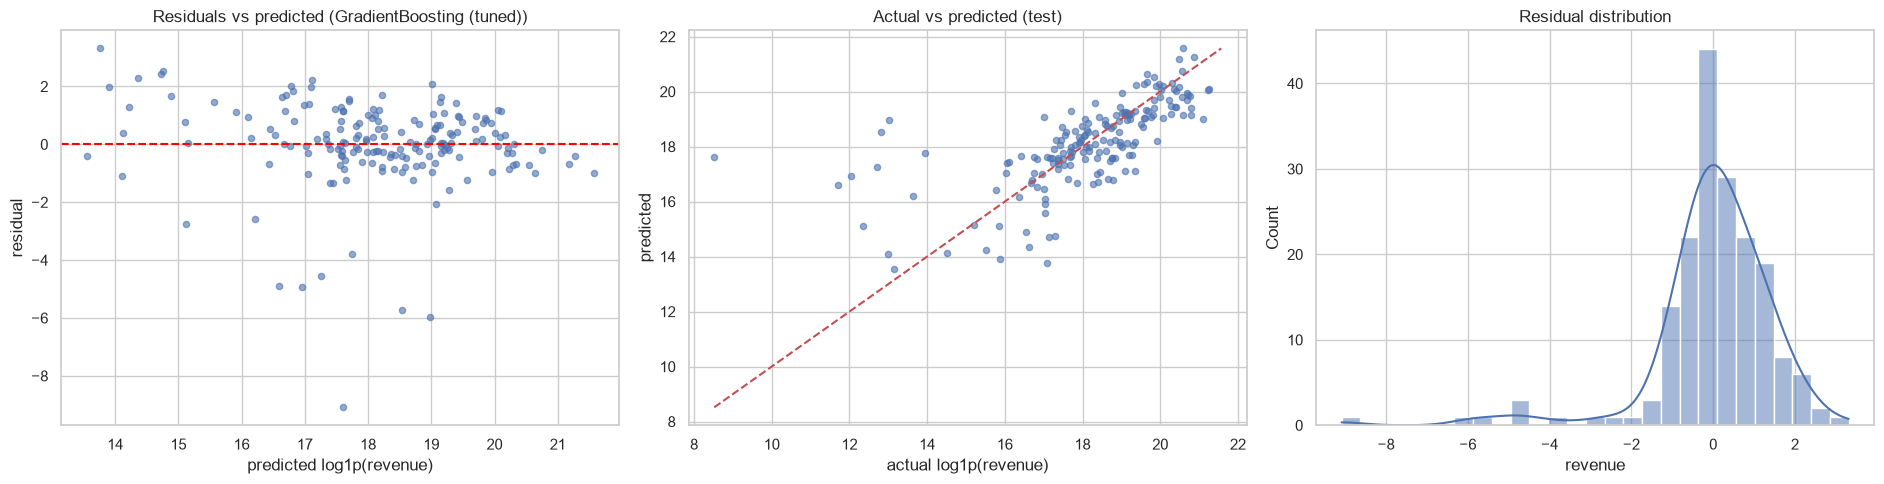

Mean residual: 0.006 | skew of residuals: -2.37
Mean residual, bottom-20% revenue films: -1.179 | rest: 0.302


,title,release_year,budget,revenue_m,pred_rev,resid
692,Damsel,2024,60000000.0,0.00,44.28,-9.09
529,The Gray Man,2022,200000000.0,0.45,174.56,-5.95
618,The Killer,2023,175000000.0,0.36,112.28,-5.74
497,The Hand of God,2021,13050000.0,0.17,22.94,-4.92
409,Mank,2020,25000000.0,0.12,16.14,-4.88
306,Marriage Story,2019,18000000.0,0.33,31.17,-4.54
245,Roma,2018,15000000.0,1.14,51.13,-3.80
417,The Courier,2020,NaN,26.00,0.95,3.31


In [27]:
pred = final_model.predict(X_test)
resid = y_test - pred
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
axes[0].scatter(pred, resid, alpha=0.6, s=20); axes[0].axhline(0, color="red", ls="--")
axes[0].set_xlabel("predicted log1p(revenue)"); axes[0].set_ylabel("residual"); axes[0].set_title(f"Residuals vs predicted ({FINAL_NAME})")
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
axes[1].scatter(y_test, pred, alpha=0.6, s=20); axes[1].plot(lims, lims, "r--")
axes[1].set_xlabel("actual log1p(revenue)"); axes[1].set_ylabel("predicted"); axes[1].set_title("Actual vs predicted (test)")
sns.histplot(resid, kde=True, ax=axes[2]); axes[2].set_title("Residual distribution")
save_fig("p2_08_residuals.png")
low = y_test < y_test.quantile(0.2)
print(f"Mean residual: {resid.mean():.3f} | skew of residuals: {resid.skew():.2f}")
print(f"Mean residual, bottom-20% revenue films: {resid[low].mean():.3f} | rest: {resid[~low].mean():.3f}")
worst = base.loc[X_test.index].assign(pred_rev=np.expm1(pred)/1e6, revenue_m=base.loc[X_test.index, "revenue"]/1e6, resid=resid)
display(worst.reindex(worst["resid"].abs().sort_values(ascending=False).index)[["title", "release_year", "budget", "revenue_m", "pred_rev", "resid"]].head(8).round(2))
R.update(resid_mean=resid.mean(), resid_skew=resid.skew(), resid_low=resid[low].mean(), resid_rest=resid[~low].mean(),
         worst_title=worst.loc[resid.abs().idxmax(), "title"], worst_rev=float(base.loc[resid.abs().idxmax(), "revenue"]), worst_resid=resid.loc[resid.abs().idxmax()])

**What we did:** for the final model on the test set, we plotted the residuals (actual minus predicted log-revenue) against the predictions, actual against predicted values, and the distribution of residuals. We also compared the bottom 20% of films by revenue with the rest, and listed the biggest misses.

**Why:** residuals show *where* a model goes wrong, which a single score can hide.

**What we found:** the average residual is basically zero (0.006), and most points sit in an even band around the zero line. But there's a **long tail on the negative side** (skew -2.37). For the lowest-earning 20% of films the average residual is -1.18, against 0.30 for the rest, so **the model overestimates films that barely earned anything**. The worst miss is *Damsel*, a Netflix film with a reported revenue of just $5,000. Nothing in our pre-release data says "this is a streaming film", so the model can't know. A "release type" feature would be the obvious fix.

### 12.5 Model interpretation: feature importance

,importance_mean,std
budget,0.2069,0.0401
in_collection,0.0928,0.0135
budget_missing,0.0755,0.0425
primary_country,0.0680,0.0183
release_year,0.0674,0.0175
primary_company,0.0218,0.0103
n_countries,0.0085,0.0081
is_weekend_release,0.0076,0.0185
cast_size,0.0000,0.0000
n_spoken_languages,0.0000,0.0000


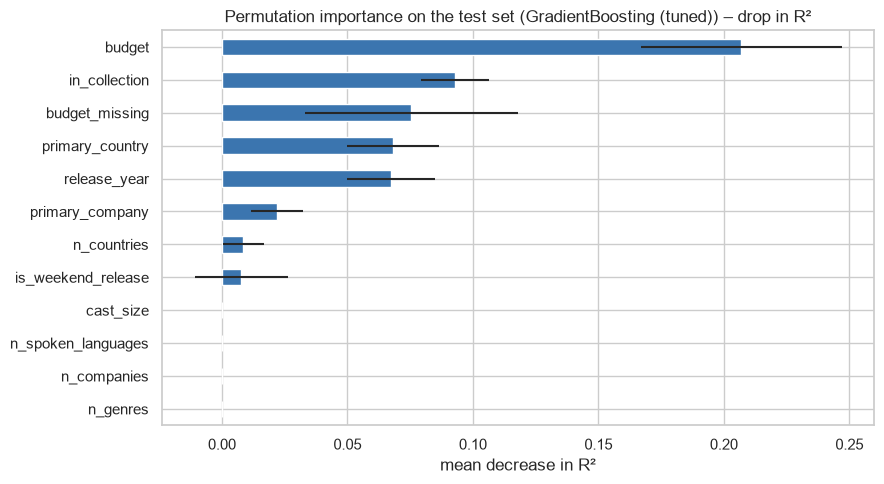

,Ridge coefficient (log-revenue per 1 std / per flag)
budget_missing,-2.923
primary_country_Japan,1.621
in_collection,0.772
primary_country_China,0.748
budget,0.742
is_weekend_release,-0.591
primary_company_infrequent_sklearn,-0.426
release_year,-0.222
crew_size,0.166
n_countries,-0.147


In [28]:
pi = permutation_importance(final_model, X_test, y_test, n_repeats=20, random_state=SEED, scoring="r2")
imp = pd.DataFrame({"importance_mean": pi.importances_mean, "std": pi.importances_std}, index=X_test.columns).sort_values("importance_mean", ascending=False)
display(imp.head(12).round(4))
plt.figure(figsize=(9, 5))
imp.head(12)[::-1]["importance_mean"].plot.barh(xerr=imp.head(12)[::-1]["std"], color="#3b75af")
plt.title(f"Permutation importance on the test set ({FINAL_NAME}) – drop in R²"); plt.xlabel("mean decrease in R²")
save_fig("p2_09_permutation_importance.png")
ridge = fitted["Ridge"].named_steps["model"]; cols = fitted["Ridge"].named_steps["select"].cols
coef = pd.Series(ridge.coef_, index=cols).sort_values(key=abs, ascending=False)
display(coef.head(10).round(3).to_frame("Ridge coefficient (log-revenue per 1 std / per flag)"))
R.update(imp1=imp.index[0], imp1_v=imp.iloc[0, 0], imp2=imp.index[1], imp2_v=imp.iloc[1, 0], imp3=imp.index[2], imp3_v=imp.iloc[2, 0],
         coef1=coef.index[0], coef1_v=coef.iloc[0], coef2=coef.index[1], coef2_v=coef.iloc[1],
         budget_coef=float(coef.get("budget", np.nan)), n_imp_pos=int((imp["importance_mean"] > 0.001).sum()))

**What we did:** we calculated **permutation importance** for the final model on the test set: shuffle one feature at a time and measure how much R² drops (repeated 20 times). We also listed the biggest Ridge coefficients to see the *direction* of each effect.

**Why:** the brief asks us to interpret the final model. Permutation importance works for any model and is measured on unseen data, while Ridge's coefficients show whether a feature pushes revenue up or down.

**What we found:** the three most important features are **budget** (R² drops by 0.207 when it's shuffled), **in_collection**, i.e. part of a franchise (0.093), and **budget_missing** (0.075). In Ridge, an unknown budget has the biggest effect (-2.92), because films without a reported budget are usually small releases. Budget itself has a positive coefficient (+0.74), so bigger budgets mean bigger revenue. The story is simple: production size and franchise status drive box office.

### 12.6 Effect of preprocessing, feature selection and leakage

In [29]:
def test_r2(pipe, Xtr_, Xte_, ytr_=y_train, log_target=True):
    pipe.fit(Xtr_, ytr_ if log_target else np.expm1(ytr_))
    p = pipe.predict(Xte_)
    return r2_score(y_test, p if log_target else np.log1p(np.clip(p, 0, None))), r2_score(np.expm1(y_test), np.expm1(p) if log_target else p)

GB = MODELS["GradientBoosting"]
abl = {}
abl["final setup (log target, selected features)"] = test_r2(full_pipe(GB, FINAL_FEATURES), X_train, X_test)
abl["all features (no feature selection)"] = test_r2(full_pipe(GB), X_train, X_test)
abl["raw $ target (no log transform)"] = test_r2(full_pipe(GB, FINAL_FEATURES), X_train, X_test, log_target=False)
raw_num = Pipeline([("pre", ColumnTransformer([("num", SimpleImputer(strategy="median"), NUM_LOG + NUM_PLAIN + DATE_NUM), ("bool", "passthrough", BOOL_COLS)])),
                    ("model", Ridge(alpha=1.0))])
with warnings.catch_warnings(record=True) as w:          # unscaled raw dollars -> ill-conditioned normal equations
    warnings.simplefilter("always")
    abl["Ridge, no log/capping/scaling/OHE"] = test_r2(raw_num, X_train, X_test)
print("Numerical warnings raised by the unscaled Ridge fit:", sum("ill-conditioned" in str(x.message) for x in w))
abl["Ridge, full preprocessing"] = test_r2(full_pipe(Ridge(alpha=1.0), FINAL_FEATURES), X_train, X_test)
Xl_tr = X_train.join(base.loc[X_train.index, LEAK_COLS]); Xl_te = X_test.join(base.loc[X_test.index, LEAK_COLS])
leak_pipe = Pipeline([("pre", ColumnTransformer([("base", make_preprocessor(), list(X_train.columns)),
                       ("leak", Pipeline([("log", FunctionTransformer(np.log1p)), ("sc", StandardScaler())]), LEAK_COLS)])), ("model", clone(GB))])
abl["WITH leaky post-release votes/popularity (not allowed)"] = test_r2(leak_pipe, Xl_tr, Xl_te)
abl_tbl = pd.DataFrame(abl, index=["test R2 (log)", "test R2 ($)"]).T
display(abl_tbl.round(4))
R.update(abl_final=abl_tbl.iloc[0, 0], abl_all=abl_tbl.iloc[1, 0], abl_raw=abl_tbl.iloc[2, 0], abl_raw_d=abl_tbl.iloc[2, 1],
         abl_final_d=abl_tbl.iloc[0, 1], abl_ridge_raw=abl_tbl.iloc[3, 0], abl_ridge_full=abl_tbl.iloc[4, 0], abl_leak=abl_tbl.iloc[5, 0])

Numerical warnings raised by the unscaled Ridge fit: 1


,test R2 (log),test R2 ($)
"final setup (log target, selected features)",0.4315,0.4061
all features (no feature selection),0.4280,0.4503
raw $ target (no log transform),-1.6009,0.3591
"Ridge, no log/capping/scaling/OHE",0.3865,-0.1701
"Ridge, full preprocessing",0.4314,0.3344
WITH leaky post-release votes/popularity (not allowed),0.4655,0.5935


**What we did:** we re-trained several variations and compared their test R² to see what each step actually contributes:
- the final setup against all features (no selection);
- a raw-dollar target with no log transform;
- Ridge with no preprocessing against full preprocessing;
- Gradient Boosting *with* the leaky post-release columns.

**Why:** the brief asks us to explain the effect of preprocessing and feature selection. The leakage run shows why we were right to drop those columns.

**What we found:**
- **The log transform is the biggest win.** Training on raw dollars makes the log-scale R² collapse to -1.60 (from 0.432), because a few blockbusters dominate the error.
- **Preprocessing helps Ridge:** 0.386 without it against 0.431 with it. Without scaling, SciPy even warns about an "ill-conditioned matrix", which is a nice practical example of why scaling matters.
- **Feature selection:** with all features, Gradient Boosting scores 0.428 against 0.432 with our 10, so the smaller set loses nothing and is simpler.
- **Leakage:** adding votes and popularity would push test R² up to 0.465. It looks better, but it's cheating, because that information doesn't exist before release.

## 14. Advanced Technique #2 — Out-of-fold Target Encoding

In [30]:
print("Distinct values in train:", {c: X_train[c].nunique() for c in ["director", "primary_company"]})
print("Directors with only one film in train:", int((X_train["director"].value_counts() == 1).sum()))
te_rows = {}
for label, pipe in [("baseline: OHE grouped (no director)", full_pipe(clone(GB))),
                    ("+ one-hot director (min_frequency=10)", None),
                    ("+ out-of-fold target encoding (director, primary_company)", full_pipe(clone(GB), te_cols=("director", "primary_company")))]:
    if pipe is None:
        pre = make_preprocessor(cat_cols=CAT_COLS + ["director"]).set_output(transform="pandas")
        pipe = Pipeline([("prep", pre), ("model", clone(GB))])
    cvr = cross_validate(pipe, X_train, y_train, cv=cv5, scoring="r2")["test_score"]
    pipe.fit(X_train, y_train)
    n_cols = pipe.named_steps["prep"].transform(X_train.head(5)).shape[1]
    te_rows[label] = {"n_model_columns": n_cols, "CV R2 mean": cvr.mean(), "CV R2 std": cvr.std(),
                      "test R2 (log)": r2_score(y_test, pipe.predict(X_test)),
                      "test MAE ($m)": mean_absolute_error(np.expm1(y_test), np.expm1(pipe.predict(X_test)))/1e6}
te_tbl = pd.DataFrame(te_rows).T
display(te_tbl.round(4))
te_pipe = pipe
enc = te_pipe.named_steps["prep"].named_transformers_["te"].named_steps["te"]
dir_map = pd.Series(enc.encodings_[0], index=enc.categories_[0]).sort_values(ascending=False)
print("Highest encoded directors (smoothed mean log-revenue):"); display(dir_map.head(5).round(3).to_frame("encoding"))
print(f"Unique directors: {X_train['director'].nunique()} would need that many one-hot columns; target encoding uses 1 column each.")
R.update(n_dir=int(X_train["director"].nunique()), n_comp=int(X_train["primary_company"].nunique()),
         n_dir_single=int((X_train["director"].value_counts() == 1).sum()),
         te_base_cv=te_tbl.iloc[0]["CV R2 mean"], te_ohe_cv=te_tbl.iloc[1]["CV R2 mean"], te_cv=te_tbl.iloc[2]["CV R2 mean"],
         te_base_test=te_tbl.iloc[0]["test R2 (log)"], te_ohe_test=te_tbl.iloc[1]["test R2 (log)"], te_test=te_tbl.iloc[2]["test R2 (log)"],
         te_base_mae=te_tbl.iloc[0]["test MAE ($m)"], te_mae=te_tbl.iloc[2]["test MAE ($m)"],
         te_base_cols=int(te_tbl.iloc[0]["n_model_columns"]), te_ohe_cols=int(te_tbl.iloc[1]["n_model_columns"]),
         te_cols=int(te_tbl.iloc[2]["n_model_columns"]), top_dir=dir_map.index[0])

Distinct values in train: {'director': 479, 'primary_company': 332}
Directors with only one film in train: 329


,n_model_columns,CV R2 mean,CV R2 std,test R2 (log),test MAE ($m)
baseline: OHE grouped (no director),65.0,0.3917,0.0851,0.4280,125.1106
+ one-hot director (min_frequency=10),66.0,0.3937,0.1029,0.4290,127.1662
"+ out-of-fold target encoding (director, primary_company)",67.0,0.4129,0.0916,0.4843,120.2241


Highest encoded directors (smoothed mean log-revenue):


,encoding
Anthony Russo,21.607
Jiao Zi,21.543
Jared Bush,21.348
James Cameron,21.323
Aaron Horvath,21.031


Unique directors: 479 would need that many one-hot columns; target encoding uses 1 column each.


**The technique:** out-of-fold **target encoding** (scikit-learn's `TargetEncoder`, `cv=5`, `random_state = SEED`) for the director and the main production company. This technique **changes the features** the model sees.

**What in our data called for it:** the training set has 479 different directors and 332 different main companies, and 329 of those directors have just one film. One-hot encoding them would add hundreds of nearly empty columns for only 719 films. Target encoding replaces each director with a single number: a smoothed average of the log-revenue of *their other films*. It's calculated "out-of-fold", meaning each film's value comes from the other parts of the data, so no film ever sees its own revenue.

**Before and after (same Gradient Boosting settings, all features):**
- without director: cross-validated R² 0.392, test R² 0.428, test MAE $125.1 million;
- director one-hot encoded (with rare ones grouped): cross-validated R² 0.394, test R² 0.429. Almost every director is rare, so this adds just one useful column;
- **with target encoding: cross-validated R² 0.413, test R² 0.484, test MAE $120.2 million.**

**What it changed:** target encoding **improved the model**. Test R² rose by 0.056, cross-validated R² by 0.021, and the average error fell by about 5 million dollars, while adding only two columns. The highest-scoring director is Anthony Russo (the Avengers films), which shows the encoder learns sensible things. Our Advanced Technique #1 (KNN/Iterative imputation) is in Notebook 1.

## Model Training Log (required: do not edit the output)

In [31]:
TRAINING_FINISHED = dt.datetime.now()
log_rows = []
for n, p in fitted.items():
    m = metrics(y_test, p.predict(X_test))
    log_rows.append({"model": n, "test_MAE_$m": round(m["MAE_$m"], 3), "test_MSE_$m2": round(m["MSE_$m2"], 3),
                     "test_RMSE_$m": round(m["RMSE_$m"], 3), "test_R2_$": round(m["R2_$"], 4), "test_R2_log": round(m["R2_log"], 4),
                     "test_MAE_log": round(m["MAE_log"], 4)})
training_log = {
    "team_roll_numbers": ROLL_NUMBERS, "SEED": SEED, "seed_rule": "last four digits of the lowest team roll number, used for every random_state",
    "training_started": TRAINING_STARTED.isoformat(timespec="seconds"), "training_finished": TRAINING_FINISHED.isoformat(timespec="seconds"),
    "train_size": len(X_train), "test_size": len(X_test), "target": "log1p(revenue)",
    "n_features_final": len(FINAL_FEATURES), "final_model": FINAL_NAME, "test_metrics": log_rows}
print("=" * 30, "MODEL TRAINING LOG", "=" * 30)
print(json.dumps({k: v for k, v in training_log.items() if k != "test_metrics"}, indent=2))
display(pd.DataFrame(log_rows).set_index("model"))
with open(os.path.join(OUT_DIR, "model_training_log.json"), "w") as f:
    json.dump(training_log, f, indent=2, default=str)

============================== MODEL TRAINING LOG ==============================
{
  "team_roll_numbers": [
    "25L-3001",
    "25L-0004"
  ],
  "SEED": 4,
  "seed_rule": "last four digits of the lowest team roll number, used for every random_state",
  "training_started": "2026-11-21T18:54:10",
  "training_finished": "2026-11-21T18:55:46",
  "train_size": 719,
  "test_size": 180,
  "target": "log1p(revenue)",
  "n_features_final": 10,
  "final_model": "GradientBoosting (tuned)"
}


,test_MAE_$m,test_MSE_$m2,test_RMSE_$m,test_R2_$,test_R2_log,test_MAE_log
model,,,,,,
Ridge,134.574,68283.781,261.312,0.3344,0.4314,0.9246
RandomForest,132.558,59965.667,244.879,0.4155,0.4117,0.9665
GradientBoosting,134.192,60925.491,246.831,0.4061,0.4315,0.9475
GradientBoosting (tuned),139.508,75999.982,275.681,0.2592,0.4414,0.9390


**What we did:** we printed the model training log: roll numbers, SEED, training start and finish times, training and test sizes, the target, the final model, and the final **test** scores (MAE, MSE, RMSE, R²) for every model. It's also saved to `outputs/model_training_log.json`.

**Why:** the project rules require this log as proof that we trained the models ourselves. Its output must stay visible and unedited.

**What we found:** 719 training films and 180 test films (899 in total). The final model is tuned Gradient Boosting, and every random step used SEED = 4.

## Saving deliverables

In [32]:
joblib.dump(final_model, os.path.join(OUT_DIR, "final_model_pipeline.joblib"))
joblib.dump(prep, os.path.join(OUT_DIR, "preprocessing_pipeline.joblib"))
comp.round(4).to_csv(os.path.join(OUT_DIR, "model_comparison.csv"))
cv_tbl.round(4).to_csv(os.path.join(OUT_DIR, "cross_validation.csv"))
tune_cmp.round(4).to_csv(os.path.join(OUT_DIR, "tuning_comparison.csv"))
abl_tbl.round(4).to_csv(os.path.join(OUT_DIR, "ablation.csv"))
te_tbl.round(4).to_csv(os.path.join(OUT_DIR, "target_encoding_comparison.csv"))
R = {k: (float(v) if isinstance(v, (np.floating, np.integer)) else v) for k, v in R.items()}
with open(os.path.join(OUT_DIR, "p2_results.json"), "w") as f:
    json.dump(R, f, indent=2, default=str)
reloaded = joblib.load(os.path.join(OUT_DIR, "final_model_pipeline.joblib"))
assert np.allclose(reloaded.predict(X_test), final_model.predict(X_test))
print("Saved:", sorted(os.listdir(OUT_DIR)))
print("Reloaded pipeline reproduces test predictions: OK")

Saved: ['ablation.csv', 'cross_validation.csv', 'final_model_pipeline.joblib', 'model_comparison.csv', 'model_training_log.json', 'p2_results.json', 'preprocessing_pipeline.joblib', 'target_encoding_comparison.csv', 'tuning_comparison.csv']
Reloaded pipeline reproduces test predictions: OK


**What we did:** we saved the final trained pipeline (preprocessing + feature selection + model) and the preprocessing pipeline on its own, using joblib, along with all the results tables as CSV files. Then we reloaded the saved model to check that it gives exactly the same predictions.

**Why:** the brief asks for a reproducible pipeline and the evaluation results, and the reload test proves the saved file actually works.

**What we found:** every file is in `outputs/`, and the reloaded model reproduces the test predictions exactly. To use it, give `final_model_pipeline.joblib` a table of engineered features and it returns a log-revenue prediction; `np.expm1` turns that back into dollars.

## Conclusions and Limitations

**What we found.** Using only information available before a film is released, our final model (tuned Gradient Boosting) explains about 44% of the variation in log-revenue on films it has never seen (test R² 0.441, cross-validated R² 0.496). Budget, franchise membership and whether the budget is known matter most. Target encoding the director and main company improved test R² further, to 0.484.

**What made the biggest difference.** Log-transforming revenue was by far the most important step. Feature selection cut 65 columns down to 10 without losing accuracy. Tuning mostly fixed Gradient Boosting's overfitting. Votes and popularity would have raised R² to 0.465, but using them would be leakage, so we left them out.

**Limitations.**
1. **Popular films only:** we collected the most-voted films each year, so the data leans towards well-known, mostly English-language (93%) films. The model shouldn't be trusted for small independent films.
2. **Missing revenues aren't random:** 201 films with no revenue were left out, and many of them are from 2020 or 2026.
3. **Placeholder revenues:** 29 films report under $1 million (often streaming releases), and the model overestimates them.
4. **Time on sale:** 2026 films are still earning, and 2020 was hit by cinema closures, so release year partly measures how long a film has been out.
5. **Data quality:** TMDB revenue is entered by users and isn't adjusted for inflation. Things like marketing spend, reviews and competition aren't in the data at all.
6. **Small test set:** with 180 test films, differences of about 0.01 to 0.02 R² between models are within normal noise, as the cross-validation spreads show.